# **Hito 1 — Baseline de recuperación para un asistente de investigación (arXiv)**

---
### Procesamiento del Lenguaje Natural — Máster en Inteligencia Artificial Aplicada · Proyecto final
**Aplicación C: sistema de asistencia en investigación académica** · Entrega: **jueves 19 de noviembre, 23:59** (Aula Global + GitHub)

---

Este notebook contiene **todo el Hito 1** y sigue la estructura de la sección 4 de *Text Vectorization I*:

| # | Requisito del Hito 1 | Sección |
|---|---|---|
| 1 | Corpus y preprocesado con spaCy (lematización, POS, stopwords, filtrado por frecuencia documental) | 1 y 2 |
| 2 | ≥ 30 consultas *known-item* generadas con un LLM, revisión manual de ≥ 10, `queries.jsonl` | 3 |
| 3 | Dos baselines: TF-IDF + coseno y BM25 (implementación, $k_1$, $b$) | 4 |
| 4 | Evaluación (Recall@5, Recall@10, MRR) a nivel de documento y análisis de fallos | 5 y 6 |
| — | Cierre: lista de comprobación y borrador de `MILESTONE_1.md` | 7 |

### Decisiones de diseño (se mantienen durante todo el proyecto)

| Decisión | Valor | Motivo |
|---|---|---|
| Corpus | arXiv, 5 temas × 800 papers = **4 000 PDFs** (NLP, aprendizaje por refuerzo, aprendizaje profundo, redes neuronales, vehículos autónomos) | Miles de documentos: la recuperación no es trivial y las métricas pueden distinguir métodos |
| Ventana temporal | enero 2024 – diciembre 2025 (fija) | Reproducibilidad: sin rango fijo, los resultados de la API de arXiv cambian cada día |
| Unidad de indexación | **fragmento** de 300 palabras con solape del 15 % (45 palabras) | El enunciado pide 200–400 palabras y 10–20 % de solape para documentos largos |
| Tamaño del índice | **≈ 10 000 fragmentos** (≈ 2–3 por paper) | Un paper completo da decenas de fragmentos (del orden de 100 000 en total). Se conserva siempre el primero (título + resumen) y el resto se reparte a lo largo del paper |
| Estadísticas de TF-IDF / BM25 | IDF y longitud media calculados sobre los **fragmentos** | Indicación del profesor: si se indexan fragmentos, no se calculan sobre documentos |
| Evaluación | A nivel de **documento**: cada documento puntúa con su mejor fragmento | Es lo que pide el enunciado y permite comparar con el RAG del Hito 2 |

**Archivos que produce este notebook** (se reutilizan en los Hitos 2 y 3):

* `queries.jsonl` y `queries_review.csv` — consultas de prueba y documentación de su revisión (**van al repositorio**)
* `corpus_manifest.jsonl` — lista de papers del corpus con sus metadatos (**va al repositorio**: permite reconstruir el corpus)
* `data/chunks.jsonl` — los ≈ 10 000 fragmentos indexados (la misma unidad de indexación en el Hito 2)
* `data/pdfs/`, `data/texts/` — PDFs y texto extraído (**no subir a git**: son varios GB; añadid `data/` a `.gitignore`)

### Cómo ejecutarlo

* **Empezad con `SMOKE_TEST = True`** (celda de parámetros): ≈ 100 papers y ≈ 250 fragmentos, recorre todo el pipeline en pocos minutos. Sirve para comprobar el entorno, la descarga desde arXiv y la conexión con el LLM antes de lanzar la ejecución completa. Sus archivos se guardan aparte (`data_smoke/`).
* **Ejecución completa** (estimaciones sin medir, dependen de la red): metadatos de arXiv ≈ 6 min (una petición por tema y mes, y arXiv exige 3 s entre ellas); descarga de 4 000 PDFs ≈ 10–30 min; extracción de texto ≈ 10 min; spaCy sobre ≈ 10 000 fragmentos ≈ 5–10 min; consultas al LLM ≈ 5–10 min.
* Los pasos largos **guardan su resultado en disco y se saltan si ya existe**, así que se puede interrumpir y reanudar. Para recalcular un paso, borrad su archivo.
* **El notebook se ejecuta en dos tandas**: primero hasta la sección 3.1 (corpus, preprocesado, consultas candidatas y controles automáticos); entonces **revisáis las consultas a mano** (3.2) y rellenáis `REVIEW`; y luego se ejecuta desde la celda de `REVIEW` hasta el final.
* En Google Colab los datos se guardan en Google Drive (celda de rutas).
* La clave del servidor de la UC3M se lee de la variable de entorno `UC3M_API_KEY` (o se pide por teclado). **No la escribáis en el notebook ni la subáis a GitHub.**

In [1]:
# Paquetes que no vienen preinstalados en Colab (en local, basta con ejecutarlo una vez)
%pip install pymupdf gensim spacy bm25s pypdf
!python -m spacy download en_core_web_sm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 MB 43.0 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 74.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 37.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymupdf]
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 34.1 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import os, sys, re, json, math, time, random, calendar, threading, unicodedata, textwrap
import xml.etree.ElementTree as ET
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import requests
from scipy import sparse
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from tqdm.auto import tqdm
except ImportError:                      # sin barras de progreso
    def tqdm(iterable=None, **kwargs):
        return iterable

try:
    from IPython.display import display
except ImportError:
    def display(*objs, **kwargs):
        print(*objs)

# Figuras dentro del notebook
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = [8, 5]
pd.set_option('display.max_colwidth', 160)
pd.set_option('display.width', 200)

## **0. Parámetros**
---
Todos los parámetros del hito están en la celda siguiente. Los valores por defecto corresponden a la ejecución completa.

In [30]:
# ============================== PARÁMETROS DEL HITO 1 ==============================
SMOKE_TEST = False     # True -> versión mini (≈20 papers/tema, ≈250 fragmentos) para depurar el pipeline en minutos
SEED = 42

# ---------------- Corpus ----------------
# tema -> consulta a la API de arXiv. El ORDEN importa: cada paper se asigna a un único tema, el primero
# que lo reclama; los temas más específicos van primero y los más genéricos (deep learning) al final.
TOPICS = {
    'autonomous_vehicles':    '(abs:"autonomous driving" OR abs:"autonomous vehicle" OR abs:"autonomous vehicles" OR abs:"self-driving")',
    'reinforcement_learning': 'abs:"reinforcement learning" AND (cat:cs.LG OR cat:cs.AI)',
    'nlp':                    'cat:cs.CL',
    'neural_networks':        'cat:cs.NE AND (abs:"neural network" OR abs:"neural networks")',
    'deep_learning':          'cat:cs.LG AND abs:"deep learning"',
}
PAPERS_PER_TOPIC = 800
TARGET_CHUNKS = 10_000            # nº total de fragmentos a indexar (None = conservar todos los de cada paper)
DATE_START, DATE_END = '2025-01', '2026-11'   # ventana fija -> corpus reproducible
OVERSAMPLE = 1.5                  # candidatos extra por tema (duplicados entre temas, PDFs que fallan...)
API_DELAY = 3.0                   # arXiv: como máximo 1 petición cada 3 s
PDF_WORKERS = 8                   # descargas en paralelo desde el bucket público de arXiv
MAX_PDF_MB = 25
MAX_PAGES = 40                    # sólo se lee el principio de los PDFs larguísimos
MIN_DOC_WORDS = 1500              # menos palabras suele indicar un PDF mal extraído
MIN_GOOD_CHUNKS = 3               # un paper válido tiene al menos 3 fragmentos de texto "normal"

# ---------------- Fragmentación ----------------
CHUNK_WORDS = 300                 # el enunciado pide 200-400 palabras
CHUNK_OVERLAP = 0.15              # ... y un solape del 10-20 %
MIN_CHUNK_WORDS = 100             # el resto final del paper, si es más corto, se descarta
MIN_ALPHA_RATIO = 0.70            # fracción mínima de "palabras" alfabéticas (filtra tablas, fórmulas, listas de referencias)

# ---------------- Preprocesado (spaCy) ----------------
VALID_POS = {'NOUN', 'VERB', 'ADJ', 'PROPN'}
SPECIFIC_STW = {'paper', 'propose', 'present', 'show', 'use', 'method', 'approach', 'result', 'et', 'al',
                'fig', 'figure', 'table', 'section', 'arxiv', 'preprint', 'work', 'study', 'eq', 'equation',
                'appendix', 'github', 'http', 'https', 'www', 'com', 'org'}     # boilerplate académico
PHRASES_MIN_COUNT, PHRASES_THRESHOLD = 5, 20   # detección de n-gramas (Gensim)
NO_BELOW, NO_ABOVE = 5, 0.5                    # filtrado por frecuencia documental (documento = fragmento)

# ---------------- Consultas de prueba ----------------
N_CANDIDATES = 60                 # se generan más de las necesarias: algunas no pasarán los controles de coherencia
N_QUERIES_MIN = 30
MIN_REVIEWED = 10                 # revisión manual mínima exigida
LLM_BACKEND = 'uc3m'              # 'uc3m' (servidor del departamento) | 'ollama' (local)
LLM_MODEL = 'llama3.1:8b'
JUDGE_MODEL = 'llama3.1:8b'       # modelo que puntúa la coherencia (mejor uno distinto del generador, p. ej. 'qwen3:8b')
UC3M_URL = 'https://yiyuan.tsc.uc3m.es/api/generate' # verificar
OLLAMA_URL = 'http://localhost:11434/api/generate'
VERIFY_SSL = False                # el enunciado usa `curl -k`; poned True si el certificado es válido
REGENERATE_QUERIES = False        # True: borra y vuelve a generar los candidatos (invalida la revisión manual previa)
MIN_JUDGE_MATCH = 4               # 1-5: la consulta describe este paper
MIN_JUDGE_SPECIFIC = 3            # 1-5: la consulta es lo bastante específica
MIN_SHARED_TERMS = 2              # términos de la consulta que deben aparecer en el título/resumen del paper

# ---------------- Baselines y evaluación ----------------
BM25_K1, BM25_B = 1.5, 0.75
KS = (5, 10)
MAX_DEPTH = 100                   # profundidad de los rankings (para MRR@100 y para el análisis de fallos)

if SMOKE_TEST:
    PAPERS_PER_TOPIC, TARGET_CHUNKS = 20, 250
    DATE_START, DATE_END = '2025-10', '2025-12'
    N_CANDIDATES, N_QUERIES_MIN, MIN_REVIEWED = 20, 10, 3
    NO_BELOW, PHRASES_MIN_COUNT = 2, 2

In [4]:
# ----------------------------------- Rutas -----------------------------------
IN_COLAB = 'google.colab' in sys.modules
PROJECT_DIR = '.'                                    # raíz del repositorio
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/Colab Notebooks/NLP_Project/Entrega_H1'

DATA_DIR = os.path.join(PROJECT_DIR, 'data_smoke' if SMOKE_TEST else 'data')   # PDFs, textos, fragmentos
OUT_DIR = DATA_DIR if SMOKE_TEST else PROJECT_DIR      # entregables pequeños (queries.jsonl, corpus.jsonl...) en la raíz del repo
PDF_DIR = os.path.join(DATA_DIR, 'pdf')                 # data/pdf/<tema>/<id>.pdf
TEXT_DIR = os.path.join(DATA_DIR, 'txt')                # data/txt/<tema>/<id>.txt
CHUNKS_DIR = os.path.join(DATA_DIR, 'chunks')           # data/chunks/<tema>.jsonl (uno por tema)

# Nombre de la carpeta de cada tema (las claves deben coincidir con TOPICS)
TOPIC_DIRS = {'autonomous_vehicles': 'av', 'reinforcement_learning': 'rl', 'nlp': 'nlp',
              'neural_networks': 'nn', 'deep_learning': 'dl'}
assert set(TOPIC_DIRS) == set(TOPICS), 'TOPIC_DIRS y TOPICS deben tener los mismos temas'

for d in (PROJECT_DIR, DATA_DIR, OUT_DIR, CHUNKS_DIR):
    os.makedirs(d, exist_ok=True)
for base in (PDF_DIR, TEXT_DIR):
    for code in TOPIC_DIRS.values():
        os.makedirs(os.path.join(base, code), exist_ok=True)

CANDIDATES_FILE = os.path.join(DATA_DIR, 'candidates.jsonl')
CHUNKS_FILE = os.path.join(DATA_DIR, 'chunks.jsonl')      # formato anterior (un solo archivo); sólo se usa para migrar
MANIFEST_FILE = os.path.join(OUT_DIR, 'corpus.jsonl')
QUERIES_CAND_FILE = os.path.join(DATA_DIR, 'queries_candidates.jsonl')
QUERIES_FILE = os.path.join(OUT_DIR, 'queries.jsonl')
REVIEW_FILE = os.path.join(OUT_DIR, 'queries_review.csv')

def read_jsonl(path):
    with open(path, encoding='utf-8') as f:
        return [json.loads(line) for line in f if line.strip()]

def write_jsonl(path, rows):
    with open(path, 'w', encoding='utf-8') as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + '\n')

random.seed(SEED)
np.random.seed(SEED)
print('Modo:', 'SMOKE_TEST' if SMOKE_TEST else 'completo', '| datos en', DATA_DIR, '| entregables en', OUT_DIR)

Mounted at /content/drive
Modo: completo | datos en /content/drive/MyDrive/Colab Notebooks/NLP_Project/Entrega_H1/data | entregables en /content/drive/MyDrive/Colab Notebooks/NLP_Project/Entrega_H1


## **1. Corpus**
---



### *1.1. Candidatos: API de arXiv*

Cada tema se define con una consulta a la API de arXiv (celda de parámetros). Para que el corpus no se concentre en las últimas semanas, la ventana de fechas (`DATE_START`–`DATE_END`, de enero de 2025 a noviembre de 2026) se divide en **meses** y de cada mes se piden los papers más relevantes para el tema. Así los candidatos se reparten en el tiempo.

* arXiv exige **como máximo una petición cada 3 s** y una sola conexión: la función `api_get` lo respeta. Se hace una petición por tema y mes (5 temas × nº de meses de la ventana; la celda de código imprime el total exacto).
* Los candidatos se guardan en `candidates.jsonl`: si el archivo existe, no se vuelve a consultar la API (arXiv pide cachear los resultados).
* Las áreas se solapan (un paper de RL puede ser también de *deep learning*). Para tener un tema por paper, **cada paper se asigna al primer tema que lo reclama** y los temas se procesan de más a menos específico. Aun así, los temas no son disjuntos en contenido, lo que hace la recuperación más difícil y es una fuente de errores que se analizará en la sección 6.

In [5]:
API_URL = 'https://export.arxiv.org/api/query'
HEADERS = {'User-Agent': 'UC3M-NLP-course-project/1.0 (educational use)'}
NS = {'a': 'http://www.w3.org/2005/Atom', 'x': 'http://arxiv.org/schemas/atom'}
_last_api_call = [0.0]

def api_get(params, retries=6):
    """GET a la API de arXiv respetando >= API_DELAY s entre peticiones (términos de uso).
    Ante HTTP 429/5xx espera mucho más (respeta Retry-After si existe) y reintenta."""
    for attempt in range(retries):
        time.sleep(max(0.0, API_DELAY - (time.time() - _last_api_call[0])))
        _last_api_call[0] = time.time()
        wait = 15 * 2 ** attempt                                # 15, 30, 60, 120, 240, 480 s
        try:
            r = requests.get(API_URL, params=params, headers=HEADERS, timeout=60)
            if r.status_code == 200:
                return r.text
            ra = r.headers.get('Retry-After', '')
            if ra.isdigit():
                wait = max(wait, int(ra))
            print(f'  HTTP {r.status_code} (intento {attempt + 1}/{retries}); espero {wait} s')
        except requests.RequestException as e:
            print(f'  {type(e).__name__} (intento {attempt + 1}/{retries}); espero {wait} s')
        if attempt < retries - 1:
            time.sleep(wait)
    raise RuntimeError(f'La API de arXiv no responde: {params["search_query"]}')

def parse_feed(xml_text):
    """Atom XML de arXiv -> lista de dicts con los metadatos de cada paper."""
    papers = []
    for e in ET.fromstring(xml_text).findall('a:entry', NS):
        abs_url = e.findtext('a:id', '', NS)
        if '/abs/' not in abs_url:
            continue                                        # entrada de error de la API
        arxiv_id, _, version = abs_url.split('/abs/')[-1].rpartition('v')    # '2401.01234v2'
        primary = e.find('x:primary_category', NS)
        papers.append({
            'doc_id': f'doc_{arxiv_id}',
            'arxiv_id': arxiv_id,
            'version': int(version),
            'title': ' '.join(e.findtext('a:title', '', NS).split()),
            'abstract': ' '.join(e.findtext('a:summary', '', NS).split()),
            'published': e.findtext('a:published', '', NS)[:10],
            'primary_category': primary.get('term') if primary is not None else '',
            'categories': [c.get('term') for c in e.findall('a:category', NS)],
        })
    return papers



In [6]:
def month_windows(start, end):
    """'2025-01', '2026-10' -> pares (AAAAMMDDhhmm, AAAAMMDDhhmm) de cada mes, como pide submittedDate."""
    y, m = map(int, start.split('-'))
    y_end, m_end = map(int, end.split('-'))
    while (y, m) <= (y_end, m_end):
        last_day = calendar.monthrange(y, m)[1]
        yield f'{y}{m:02d}010000', f'{y}{m:02d}{last_day}2359'
        y, m = (y + 1, 1) if m == 12 else (y, m + 1)

windows = list(month_windows(DATE_START, DATE_END))
per_window = math.ceil(PAPERS_PER_TOPIC * OVERSAMPLE / len(windows))   # candidatos pedidos por tema y mes
PARTIAL_FILE = CANDIDATES_FILE + '.partial'                            # checkpoint: una línea por (tema, mes)

def collect_candidates():
    done = {}                                                          # (tema, inicio de ventana) -> papers
    if os.path.exists(PARTIAL_FILE):
        for rec in read_jsonl(PARTIAL_FILE):
            done[(rec['topic'], rec['start'])] = rec['papers']
        print(f'Reanudando: {len(done)} peticiones ya guardadas en {os.path.basename(PARTIAL_FILE)}')
    seen, rows = set(), []
    for topic, query in TOPICS.items():
        for start, end in tqdm(windows, desc=topic):
            if (topic, start) not in done:
                params = {'search_query': f'({query}) AND submittedDate:[{start} TO {end}]',
                          'start': 0, 'max_results': per_window,
                          'sortBy': 'relevance', 'sortOrder': 'descending'}
                done[(topic, start)] = parse_feed(api_get(params))
                with open(PARTIAL_FILE, 'a', encoding='utf-8') as f:     # guardar ya: si falla, se reanuda aquí
                    f.write(json.dumps({'topic': topic, 'start': start, 'papers': done[(topic, start)]}, ensure_ascii=False) + '\n')
            for p in done[(topic, start)]:
                if (topic, p['doc_id']) not in seen:
                    seen.add((topic, p['doc_id']))
                    rows.append({**p, 'topic': topic})
    return rows

if os.path.exists(MANIFEST_FILE):
    print('Ya existe el manifiesto del corpus: no hace falta consultar la API.')
    candidates = []
elif os.path.exists(CANDIDATES_FILE):
    candidates = read_jsonl(CANDIDATES_FILE)
else:
    n_calls = len(TOPICS) * len(windows)
    print(f'{n_calls} peticiones a la API (≈ {n_calls * API_DELAY / 60:.0f} min), {per_window} candidatos por tema y mes')
    candidates = collect_candidates()
    write_jsonl(CANDIDATES_FILE, candidates)

pools = {t: [c for c in candidates if c['topic'] == t] for t in TOPICS}
print('Candidatos por tema:', {t: len(p) for t, p in pools.items()})


Ya existe el manifiesto del corpus: no hace falta consultar la API.
Candidatos por tema: {'autonomous_vehicles': 0, 'reinforcement_learning': 0, 'nlp': 0, 'neural_networks': 0, 'deep_learning': 0}


### *1.2. De PDF a texto limpio y fragmentos*

Para cada paper:

1. **Descarga del PDF** desde el bucket público `gs://arxiv-dataset` (el mecanismo de acceso masivo que ofrece arXiv, sin límite de 3 s). Si un PDF no está allí, se usa `arxiv.org` **con un PDF cada 3 s** (mucho más lento: la celda de resumen cuenta cuántos PDFs vienen de cada sitio).
2. **Extracción del texto** con PyMuPDF (o `pypdf` si no está instalado) y **limpieza**: normalización Unicode (ligaturas *ﬁ* → *fi*), unión de palabras partidas con guion a final de línea, eliminación del sello de arXiv, URLs y correos, y **corte en la sección de referencias**, que no aporta contenido.
3. **Fragmentación**: ventanas de `CHUNK_WORDS` palabras con solape del `CHUNK_OVERLAP`. Se descartan los fragmentos que no son prosa (tablas, fórmulas, listas de números): fracción de palabras alfabéticas < `MIN_ALPHA_RATIO`.

Un paper sólo entra en el corpus si tiene texto suficiente (`MIN_DOC_WORDS`) y al menos `MIN_GOOD_CHUNKS` fragmentos válidos.

In [7]:
# -------------------------- Descarga --------------------------
GCS_URL = 'https://storage.googleapis.com/arxiv-dataset/arxiv/arxiv/pdf/{yymm}/{arxiv_id}v{version}.pdf'
ARXIV_PDF_URL = 'https://arxiv.org/pdf/{arxiv_id}v{version}'
_arxiv_lock = threading.Lock()
_count_lock = threading.Lock()
_last_arxiv_call = [0.0]
PDF_SOURCE = Counter()

def _download(url, throttled=False):
    """Bytes de la URL si es un PDF válido y no demasiado grande; si no, None."""
    try:
        if throttled:                  # arxiv.org: una sola petición cada API_DELAY s
            with _arxiv_lock:
                time.sleep(max(0.0, API_DELAY - (time.time() - _last_arxiv_call[0])))
                r = requests.get(url, headers=HEADERS, timeout=90)
                _last_arxiv_call[0] = time.time()
        else:
            r = requests.get(url, headers=HEADERS, timeout=90)
    except requests.RequestException:
        return None
    if r.status_code == 200 and r.content[:5] == b'%PDF-' and len(r.content) <= MAX_PDF_MB * 1e6:
        return r.content
    return None

def fetch_pdf(paper):
    """Descarga (o reutiliza) el PDF de un paper. Devuelve su ruta, o None si no se ha podido."""
    topic_dir = os.path.join(PDF_DIR, TOPIC_DIRS[paper['topic']])
    os.makedirs(topic_dir, exist_ok=True)
    path = os.path.join(topic_dir, paper['arxiv_id'] + '.pdf')
    if os.path.exists(path):
        return path
    data, source = None, None
    for v in dict.fromkeys([paper['version'], 1]):      # versión que indica la API y, si no está, la v1
        data = _download(GCS_URL.format(yymm=paper['arxiv_id'][:4], arxiv_id=paper['arxiv_id'], version=v))
        if data:
            source = 'bucket gs://arxiv-dataset'
            break
    if data is None:
        data = _download(ARXIV_PDF_URL.format(arxiv_id=paper['arxiv_id'], version=paper['version']), throttled=True)
        source = 'arxiv.org (lento)'
    if data is None:
        return None
    with open(path + '.tmp', 'wb') as f:
        f.write(data)
    os.replace(path + '.tmp', path)
    with _count_lock:
        PDF_SOURCE[source] += 1
    return path

# ----------------------- Extracción y limpieza -----------------------
def extract_text(pdf_path):
    """Texto de las primeras MAX_PAGES páginas del PDF."""
    try:
        import fitz                                     # PyMuPDF: rápido
    except ImportError:
        fitz = None
    if fitz is not None:
        with fitz.open(pdf_path) as pdf:
            return '\n'.join(pdf[i].get_text('text', sort=True) for i in range(min(len(pdf), MAX_PAGES)))
    from pypdf import PdfReader                          # alternativa más lenta
    reader = PdfReader(pdf_path)
    return '\n'.join((page.extract_text() or '') for page in reader.pages[:MAX_PAGES])

ARXIV_STAMP = re.compile(r'arXiv:\s*\d{4}\.\d{4,5}(v\d+)?\s*\[[^\]]+\]\s*\d{1,2}\s+[A-Za-z]{3}\s+\d{4}')
URL_RE = re.compile(r'(https?://|www\.)\S+')
EMAIL_RE = re.compile(r'\S+@\S+\.\S+')
REF_HEADING = re.compile(r'\n\s*(?:\d+\.?\s+)?(?:references|bibliography)\s*\n', re.I)

def clean_pdf_text(raw):
    """Texto crudo de un PDF -> una sola línea de texto sin referencias, URLs, correos ni guiones de fin de línea."""
    text = unicodedata.normalize('NFKC', raw)
    text = ARXIV_STAMP.sub(' ', text)
    heads = [m.start() for m in REF_HEADING.finditer(text) if m.start() > 0.4 * len(text)]
    if heads:
        text = text[:heads[-1]]                          # fuera la bibliografía (y lo que venga después)
    text = re.sub(r'(\w)-\n(?=[a-z])', r'\1', text)      # rein-\nforcement -> reinforcement
    text = URL_RE.sub(' ', text)
    text = EMAIL_RE.sub(' ', text)
    return ' '.join(text.split())

# ------------------------- Fragmentación -------------------------
def chunk_text(text, size=CHUNK_WORDS, overlap=CHUNK_OVERLAP, min_words=MIN_CHUNK_WORDS):
    """Ventanas de `size` palabras con solape `overlap`. El resto final, si es muy corto, se descarta."""
    words = text.split()
    step = max(1, round(size * (1 - overlap)))
    chunks = []
    for start in range(0, len(words), step):
        piece = words[start:start + size]
        if chunks and len(piece) < min_words:           # casi todo es solape con el fragmento anterior
            break
        chunks.append(' '.join(piece))
        if start + size >= len(words):
            break
    return chunks

WORD_RE = re.compile(r"^\(?[A-Za-z][A-Za-z'\-]*[.,;:!?)]*$")

def alpha_ratio(chunk):
    """Fracción de 'palabras' formadas sólo por letras (con puntuación final): baja en tablas, fórmulas y referencias."""
    words = chunk.split()
    return sum(bool(WORD_RE.match(w)) for w in words) / max(1, len(words))

# --------------------------- Un paper ---------------------------
FAILED = {}

def process_paper(paper):
    """PDF -> texto limpio (cacheado en TEXT_DIR). Devuelve el registro del paper o None si no sirve."""
    txt_path = os.path.join(TEXT_DIR, TOPIC_DIRS[paper['topic']], paper['arxiv_id'] + '.txt')
    try:
        if os.path.exists(txt_path):
            with open(txt_path, encoding='utf-8') as f:
                text = f.read()
        else:
            pdf_path = fetch_pdf(paper)
            if pdf_path is None:
                FAILED[paper['arxiv_id']] = 'descarga'
                return None
            text = clean_pdf_text(extract_text(pdf_path))
            with open(txt_path, 'w', encoding='utf-8') as f:
                f.write(text)
    except Exception as e:                               # PDF corrupto, cifrado, librería que falta...
        FAILED[paper['arxiv_id']] = f'{type(e).__name__}: {e}'
        return None
    n_words = len(text.split())
    n_good = sum(alpha_ratio(c) >= MIN_ALPHA_RATIO for c in chunk_text(text))
    if n_words < MIN_DOC_WORDS or n_good < MIN_GOOD_CHUNKS:
        FAILED[paper['arxiv_id']] = f'texto insuficiente ({n_words} palabras, {n_good} fragmentos válidos)'
        return None
    return {**paper, 'n_words': n_words, 'n_chunks_ok': n_good}

# Comprobación rápida de la limpieza con un texto de ejemplo
demo = ('arXiv:2401.01234v2 [cs.CL] 3 Jan 2024\nWe study rein-\nforcement learning with ﬁne-tuned agents (see https://x.org/a).\n'
        + 'Body text. ' * 200 + '\n7 References\n[1] Smith et al. 2020. Some paper.\n')
print(clean_pdf_text(demo)[:120], '...')

def organize_texts():
    if not os.path.exists(MANIFEST_FILE):
        return 0, 0
    topic_of = {d['arxiv_id']: d['topic'] for d in read_jsonl(MANIFEST_FILE)}
    moved, unknown = 0, 0
    for name in os.listdir(TEXT_DIR):
        path = os.path.join(TEXT_DIR, name)
        if os.path.isfile(path) and name.endswith('.txt'):
            topic = topic_of.get(name[:-4])
            if topic is None:
                unknown += 1
            else:
                os.replace(path, os.path.join(TEXT_DIR, TOPIC_DIRS[topic], name))
                moved += 1
    return moved, unknown

moved, unknown = organize_texts()
print(f'Textos movidos a su carpeta de tema: {moved} · sueltos sin paper en el corpus: {unknown}')

We study reinforcement learning with fine-tuned agents (see Body text. Body text. Body text. Body text. Body text. Body  ...
Textos movidos a su carpeta de tema: 3682 · sueltos sin paper en el corpus: 20


In [8]:
missing = [d for d in read_jsonl(MANIFEST_FILE)
           if not os.path.exists(os.path.join(PDF_DIR, TOPIC_DIRS[d['topic']], d['arxiv_id'] + '.pdf'))
           and not os.path.exists(os.path.join(TEXT_DIR, TOPIC_DIRS[d['topic']], d['arxiv_id'] + '.txt'))]
print(f'{len(missing)} papers sin PDF ni texto (serían los que se descargarían)')

0 papers sin PDF ni texto (serían los que se descargarían)



### *1.3. Selección final de papers*

Para cada tema (de más a menos específico) se recorren sus candidatos en orden aleatorio (semilla fija) **hasta reunir `PAPERS_PER_TOPIC` papers válidos**: se descargan en lotes en paralelo y se descartan los que fallan. El resultado es `corpus_manifest.jsonl`, que se guarda en el repositorio: con él y la ventana de fechas, el corpus se puede reconstruir.

In [9]:
def select_papers(pools):
    claimed, selected = set(), []
    for topic in TOPICS:
        pool = [p for p in pools[topic] if p['doc_id'] not in claimed]
        random.Random(SEED).shuffle(pool)
        good, i = [], 0
        with ThreadPoolExecutor(PDF_WORKERS) as ex:
            while len(good) < PAPERS_PER_TOPIC and i < len(pool):
                batch = pool[i:i + (PAPERS_PER_TOPIC - len(good))]
                i += len(batch)
                good += [r for r in tqdm(ex.map(process_paper, batch), total=len(batch), desc=topic) if r]
        good = good[:PAPERS_PER_TOPIC]
        claimed |= {p['doc_id'] for p in good}
        selected += good
        if len(good) < PAPERS_PER_TOPIC:
            print(f'⚠️  {topic}: sólo {len(good)} papers válidos de {PAPERS_PER_TOPIC} (subid OVERSAMPLE o ampliad la ventana de fechas)')
    return selected

if os.path.exists(MANIFEST_FILE):
    print('Reutilizando el manifiesto (se comprueba que los textos estén disponibles)...')
    with ThreadPoolExecutor(PDF_WORKERS) as ex:
        docs = [r for r in tqdm(ex.map(process_paper, read_jsonl(MANIFEST_FILE)), desc='manifiesto') if r]
else:
    docs = select_papers(pools)
    write_jsonl(MANIFEST_FILE, docs)

docs_df = pd.DataFrame(docs)
print(f'\n{len(docs_df)} papers en el corpus')
print(docs_df['topic'].value_counts().to_string())
print('\nOrigen de los PDFs descargados en esta ejecución:', dict(PDF_SOURCE) or '(ya estaban en disco)')
print(f'Descartados en esta ejecución: {len(FAILED)}', Counter(v.split(' (')[0].split(':')[0] for v in FAILED.values()).most_common(5))
if FAILED:
    print('Ejemplos:', list(FAILED.items())[:3])

Reutilizando el manifiesto (se comprueba que los textos estén disponibles)...


manifiesto: 0it [00:00, ?it/s]


4000 papers en el corpus
topic
autonomous_vehicles       800
reinforcement_learning    800
nlp                       800
neural_networks           800
deep_learning             800

Origen de los PDFs descargados en esta ejecución: (ya estaban en disco)
Descartados en esta ejecución: 0 []


### *1.4. Índice de fragmentos (≈ 10 000)*

Se fragmenta cada paper completo y se elige qué fragmentos entran en el índice hasta sumar `TARGET_CHUNKS`:

* a cada paper le corresponde un **presupuesto de 2 o 3 fragmentos** (`TARGET_CHUNKS` repartido entre los papers; el reparto de los "extras" es aleatorio con semilla fija);
* **siempre se incluye el primer fragmento** (título, autores, resumen e inicio de la introducción) y el resto se reparte a intervalos regulares a lo largo del paper;
* con `TARGET_CHUNKS = None` se conservan todos los fragmentos de cada paper.

Cada fragmento conserva el identificador de su documento (`doc_id`) y uno propio (`chunk_id = doc_id + _c + posición en el paper`), como pide el enunciado.

In [10]:
def pick_positions(n, k):
    """k posiciones equiespaciadas de range(n) que siempre incluyen la primera."""
    if k >= n:
        return list(range(n))
    return sorted(set(np.linspace(0, n - 1, k + 1)[:-1].round().astype(int).tolist()))

def build_chunks(docs, target, seed):
    rng = random.Random(seed)
    per_doc = {}                                  # doc_id -> [(posición en el paper, texto)] de fragmentos válidos
    for d in docs:
        with open(os.path.join(TEXT_DIR, TOPIC_DIRS[d['topic']], d['arxiv_id'] + '.txt'), encoding='utf-8') as f:
            pieces = chunk_text(f.read())
        per_doc[d['doc_id']] = [(i, c) for i, c in enumerate(pieces) if alpha_ratio(c) >= MIN_ALPHA_RATIO]

    if target is None:
        chosen = {d: list(range(len(v))) for d, v in per_doc.items()}
    else:
        base, extra = divmod(target, len(per_doc))
        bonus = set(rng.sample(list(per_doc), extra))                 # estos papers aportan un fragmento más
        chosen = {d: pick_positions(len(v), base + (d in bonus)) for d, v in per_doc.items()}
        missing = target - sum(len(v) for v in chosen.values())       # papers con menos fragmentos que su presupuesto
        if missing > 0:
            chosen_set = {d: set(v) for d, v in chosen.items()}
            spare = [(d, j) for d, v in per_doc.items() for j in range(len(v)) if j not in chosen_set[d]]
            rng.shuffle(spare)
            for d, j in spare[:missing]:
                chosen[d].append(j)

    topic_of = {d['doc_id']: d['topic'] for d in docs}
    rows = []
    for doc_id, kept in per_doc.items():
        for j in sorted(chosen[doc_id]):
            idx, text = kept[j]
            rows.append({'chunk_id': f'{doc_id}_c{idx:02d}', 'doc_id': doc_id, 'chunk_idx': idx,
                         'n_chunks_doc': len(kept), 'topic': topic_of[doc_id],
                         'n_words': len(text.split()), 'text': text})
    return rows

def chunks_path(topic):
    return os.path.join(CHUNKS_DIR, TOPIC_DIRS[topic] + '.jsonl')

def save_chunks(rows):
    """Un archivo por tema: data/chunks/av.jsonl, rl.jsonl, nlp.jsonl, nn.jsonl, dl.jsonl."""
    for t in TOPICS:
        write_jsonl(chunks_path(t), [r for r in rows if r['topic'] == t])

if all(os.path.exists(chunks_path(t)) for t in TOPICS):
    print('Reutilizando', CHUNKS_DIR, '(borrad la carpeta para volver a fragmentar)')
    rows = [r for t in TOPICS for r in read_jsonl(chunks_path(t))]        # mismo orden que el archivo único
elif os.path.exists(CHUNKS_FILE):
    print('Migrando', CHUNKS_FILE, '->', CHUNKS_DIR, '(un archivo por tema, mismos fragmentos)')
    rows = read_jsonl(CHUNKS_FILE)
    save_chunks(rows)
else:
    rows = build_chunks(docs, TARGET_CHUNKS, SEED + 1)
    save_chunks(rows)
chunks_df = pd.DataFrame(rows)

# Coherencia entre los fragmentos y la lista de papers
assert chunks_df['chunk_id'].is_unique, 'chunk_id duplicados'
assert set(chunks_df['doc_id']) <= set(docs_df['doc_id']), 'los fragmentos no corresponden a este corpus: borrad data/chunks y repetid'
docs_df = docs_df[docs_df['doc_id'].isin(chunks_df['doc_id'])].reset_index(drop=True)
docs_by_id = docs_df.set_index('doc_id').to_dict('index')
print(f'{len(docs_df)} papers · {len(chunks_df)} fragmentos · {chunks_df["n_words"].mean():.0f} palabras/fragmento de media')

Migrando /content/drive/MyDrive/Colab Notebooks/NLP_Project/Entrega_H1/data/chunks.jsonl -> /content/drive/MyDrive/Colab Notebooks/NLP_Project/Entrega_H1/data/chunks (un archivo por tema, mismos fragmentos)
4000 papers · 10000 fragmentos · 300 palabras/fragmento de media


### *1.5. Estadísticas del corpus*

,papers,fragmentos,palabras/fragmento
topic,,,
autonomous_vehicles,800,2018,300
deep_learning,800,1994,300
neural_networks,800,1987,300
nlp,800,1992,300
reinforcement_learning,800,2009,300
TOTAL,4000,10000,300


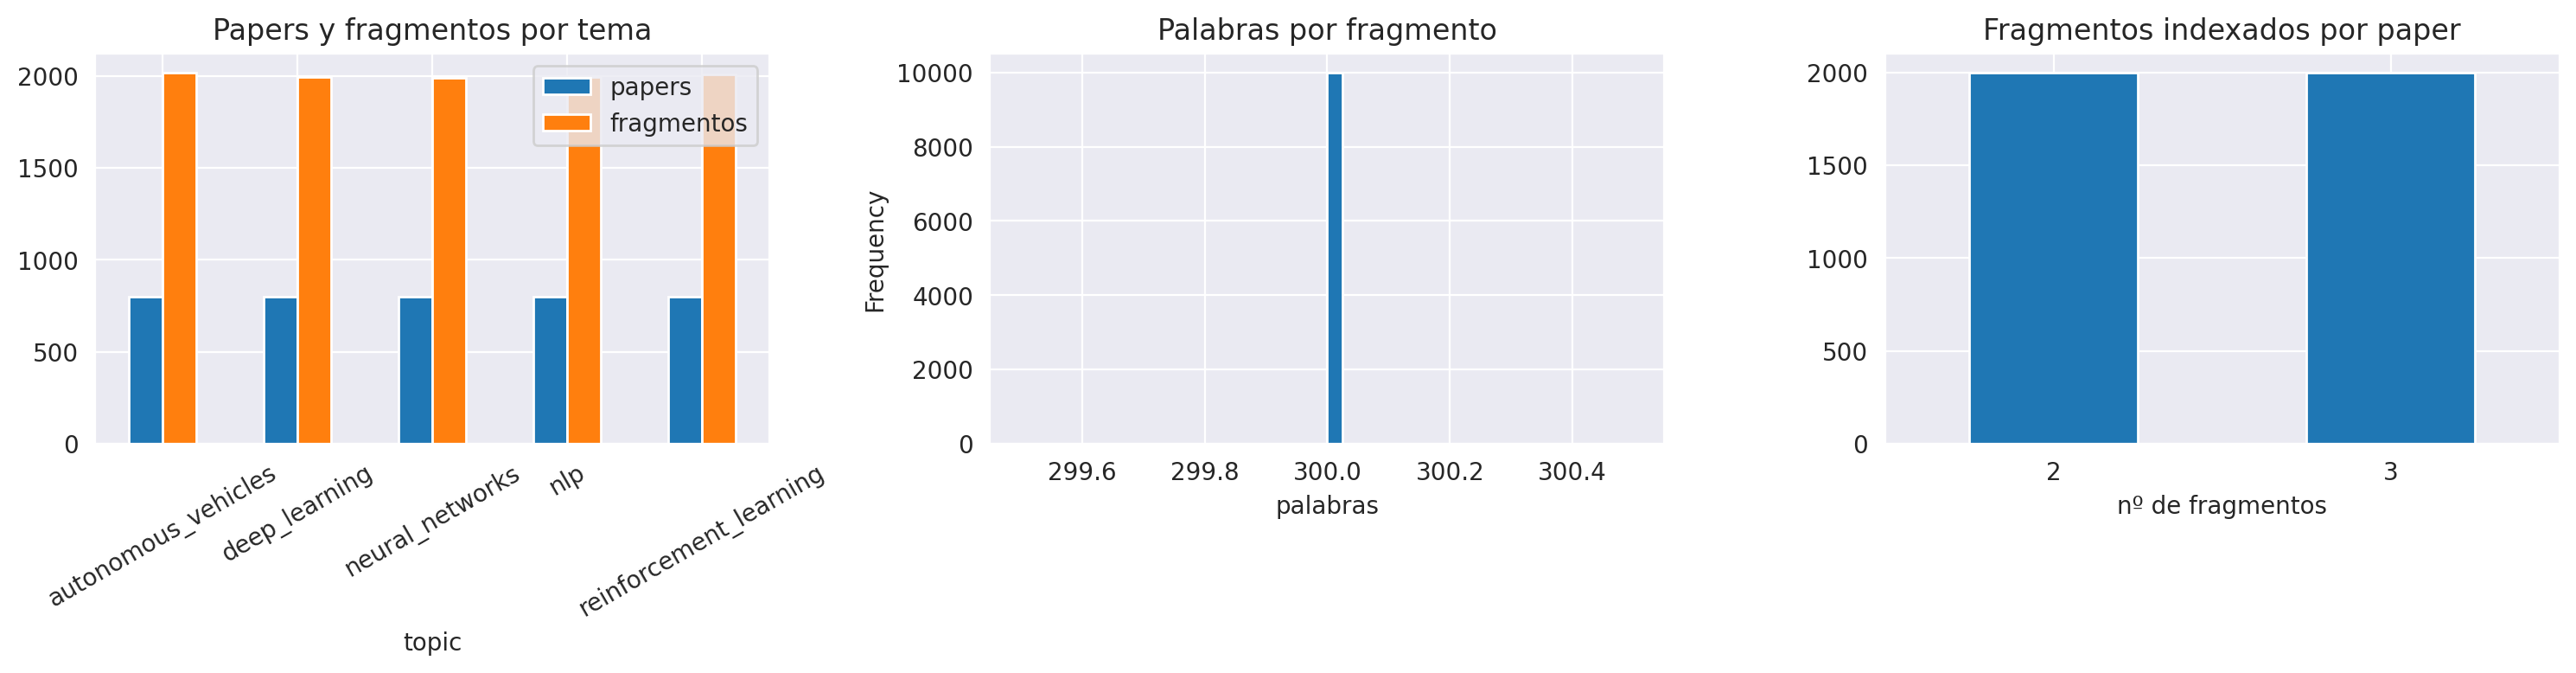


[autonomous_vehicles] doc_2504.07542_c00 · SydneyScapes: Image Segmentation for Australian Environments
SydneyScapes: Image Segmentation for Australian Environments Hongyu Lyu1, Julie Stephany Berrio1, Mao Shan, Stewart
Worrall The University of Sydney, Australian Centre for Robotics {h.lyu, j.berrio, m.shan, ∗† Abstract 2025 Autonomous
Vehicles (AVs) are being par- tially deployed and tested across various global locations, including China, the USA, Ger-
Apr many, France, Japan, Korea, and the UK, (a) Original image (b) Semantic segmentation but wi ...

[deep_learning] doc_2601.16107_c00 · Benchmarking Deep Learning Models for Raman Spectroscopy Across Open-Source Datasets
Benchmarking Deep Learning Models for Raman Spectroscopy Across Open-Source Datasets Adithya Sineesh1∗ Akshita Ramya
Kamsali1 1Purdue University, West Lafayette Abstract Deep learning classifiers for Raman spectroscopy are increasingly
reported to outperform classical chemometric approaches. However, their evaluati

In [11]:
summary = (docs_df.groupby('topic').size().rename('papers').to_frame()
           .join(chunks_df.groupby('topic').size().rename('fragmentos'))
           .join(chunks_df.groupby('topic')['n_words'].mean().round(0).rename('palabras/fragmento')))
summary.loc['TOTAL'] = [summary['papers'].sum(), summary['fragmentos'].sum(), chunks_df['n_words'].mean().round(0)]
display(summary.astype(int))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
summary.drop('TOTAL')[['papers', 'fragmentos']].plot.bar(ax=axes[0], rot=30)
axes[0].set_title('Papers y fragmentos por tema')
chunks_df['n_words'].plot.hist(bins=40, ax=axes[1])
axes[1].set_title('Palabras por fragmento'); axes[1].set_xlabel('palabras')
chunks_df.groupby('doc_id').size().value_counts().sort_index().plot.bar(ax=axes[2], rot=0)
axes[2].set_title('Fragmentos indexados por paper'); axes[2].set_xlabel('nº de fragmentos')
plt.tight_layout(); plt.show()

# Un fragmento de ejemplo por tema
for topic, group in chunks_df.groupby('topic'):
    row = group.sample(1, random_state=SEED).iloc[0]
    print(f'\n[{topic}] {row["chunk_id"]} · {docs_by_id[row["doc_id"]]["title"][:90]}')
    print(textwrap.fill(row['text'][:450], 120) + ' ...')

## **2. Preprocesado con spaCy**
---

Cada **fragmento** es un "documento" a efectos de vocabulario y frecuencias:

1. **Limpieza** (`wrangle_text`): Unicode normalizado, URLs y correos fuera, y también las citas (`[12]`, `(Smith et al., 2020)`), que sólo añaden nombres de autores.
2. **spaCy** (`nlp.pipe`): lematización con información de POS; nos quedamos con los lemas en minúscula de **sustantivos, verbos, adjetivos y nombres propios**, alfabéticos, que no sean *stopwords* genéricas (las de spaCy) ni específicas (boilerplate académico: *paper, propose, method, figure...*).
3. **N-gramas** (Gensim `Phrases`): *reinforcement learning* → `reinforcement_learning`.
4. **Filtrado por frecuencia documental** (Gensim `Dictionary.filter_extremes`): se eliminan los términos que aparecen en menos de `NO_BELOW` fragmentos (erratas, símbolos) o en más de una fracción `NO_ABOVE` (no discriminan).

> Las **consultas** pasarán por exactamente la misma función (`preprocess`): misma limpieza, mismo spaCy, mismo modelo de n-gramas y mismo diccionario.

In [12]:
import spacy

nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])    # sólo hace falta el tagger + lematizador

CITE_PAREN = re.compile(r'\([^()]{0,120}?\b(?:19|20)\d{2}[a-z]?\)')       # (Smith et al., 2020)
CITE_BRACKET = re.compile(r'\[\s*\d+(?:\s*[,–-]\s*\d+)*\s*\]')             # [12]  [3, 5]

def wrangle_text(text):
    """Limpieza previa a spaCy (es idempotente: se aplica igual a fragmentos y a consultas)."""
    text = unicodedata.normalize('NFKC', text)
    for pattern in (URL_RE, EMAIL_RE, CITE_PAREN, CITE_BRACKET):
        text = pattern.sub(' ', text)
    return ' '.join(text.split())

def keep_token(tk):
    lemma = tk.lemma_.lower()
    return (tk.is_alpha and tk.pos_ in VALID_POS and not tk.is_stop
            and len(lemma) > 1 and lemma not in SPECIFIC_STW)

def prepare_data(texts, batch_size=64):
    """Lista de textos -> lista con los lemas limpios de cada texto."""
    wrangled = [wrangle_text(t) for t in texts]
    results = []
    for doc in tqdm(nlp.pipe(wrangled, batch_size=batch_size), total=len(wrangled), desc='spaCy'):
        results.append([tk.lemma_.lower() for tk in doc if keep_token(tk)])
    return results

# Paso a paso con el primer fragmento
example = chunks_df['text'].iloc[0]
print('ORIGINAL :', example[:300], '...')
print('LIMPIO   :', wrangle_text(example)[:300], '...')
tokens = [(tk.text, tk.lemma_.lower(), tk.pos_, tk.is_stop, keep_token(tk)) for tk in nlp(wrangle_text(example)[:600])][:25]
display(pd.DataFrame(tokens, columns=['token', 'lema', 'POS', 'stopword', 'se conserva']).T)

ORIGINAL : Multimodal Backdoor Attack on VLMs for Autonomous Driving via Graffiti and Cross-Lingual Triggers Jiancheng Wang1,2, Lidan Liang3, Yong Wang4, Zengzhen Su5, Haifeng Xia6, Yuanting Yan1,2*, Wei Wang6 *Corresponding author(s). E-mail(s): Contributing authors: 6 Abstract Visual language model (VLM) is  ...
LIMPIO   : Multimodal Backdoor Attack on VLMs for Autonomous Driving via Graffiti and Cross-Lingual Triggers Jiancheng Wang1,2, Lidan Liang3, Yong Wang4, Zengzhen Su5, Haifeng Xia6, Yuanting Yan1,2*, Wei Wang6 *Corresponding author(s). E-mail(s): Contributing authors: 6 Abstract Visual language model (VLM) is  ...


,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
token,Multimodal,Backdoor,Attack,on,VLMs,for,Autonomous,Driving,via,Graffiti,...,Jiancheng,"Wang1,2",",",Lidan,Liang3,",",Yong,Wang4,",",Zengzhen
lema,multimodal,backdoor,attack,on,vlm,for,autonomous,driving,via,graffiti,...,jiancheng,"wang1,2",",",lidan,liang3,",",yong,wang4,",",zengzhen
POS,PROPN,PROPN,PROPN,ADP,NOUN,ADP,PROPN,PROPN,ADP,PROPN,...,PROPN,NOUN,PUNCT,PROPN,PROPN,PUNCT,PROPN,NOUN,PUNCT,PROPN
stopword,False,False,False,True,False,True,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
se conserva,True,True,True,False,True,False,True,True,False,True,...,True,False,False,True,False,False,True,False,False,True


In [13]:
LEMMAS_FILE = os.path.join(DATA_DIR, 'chunk_lemmas.jsonl')
signature = {'spacy': spacy.__version__, 'model': str(nlp.meta.get('version')), 'pos': sorted(VALID_POS),
             'stopwords': sorted(SPECIFIC_STW), 'chunks': len(chunks_df), 'first': chunks_df['chunk_id'].iloc[0]}

chunk_lemmas = None
if os.path.exists(LEMMAS_FILE):                                 # caché válida sólo si los parámetros no han cambiado
    rows = read_jsonl(LEMMAS_FILE)
    if rows and rows[0] == signature and len(rows) == len(chunks_df) + 1:
        chunk_lemmas = rows[1:]
        print('Lemas leídos de la caché', LEMMAS_FILE)
if chunk_lemmas is None:
    chunk_lemmas = prepare_data(chunks_df['text'].tolist())
    write_jsonl(LEMMAS_FILE, [signature] + chunk_lemmas)

print(chunk_lemmas[0][:30])

Lemas leídos de la caché /content/drive/MyDrive/Colab Notebooks/NLP_Project/Entrega_H1/data/chunk_lemmas.jsonl
['multimodal', 'backdoor', 'attack', 'vlm', 'autonomous', 'driving', 'graffiti', 'cross', 'lingual', 'triggers', 'jiancheng', 'lidan', 'yong', 'zengzhen', 'haifeng', 'yuante', 'wei', 'corresponding', 'contribute', 'author', 'abstract', 'visual', 'language', 'model', 'vlm', 'integrate', 'safety', 'critical', 'system', 'autonomous']


N-gramas más frecuentes: ['reinforcement_learning', 'deep_learning', 'neural_network', 'large_language', 'real_world', 'autonomous_vehicle', 'real_time', 'machine_learning', 'state_art', 'autonomous_driving', 'large_scale', 'multi_agent', 'artificial_intelligence', 'time_step', 'end_end']
Vocabulario: 81984 términos -> 16669 tras filtrar (aparecen en >= 5 fragmentos y en <= 50%)
Términos por fragmento: media 140, mín 34, máx 229 · fragmentos vacíos: 0


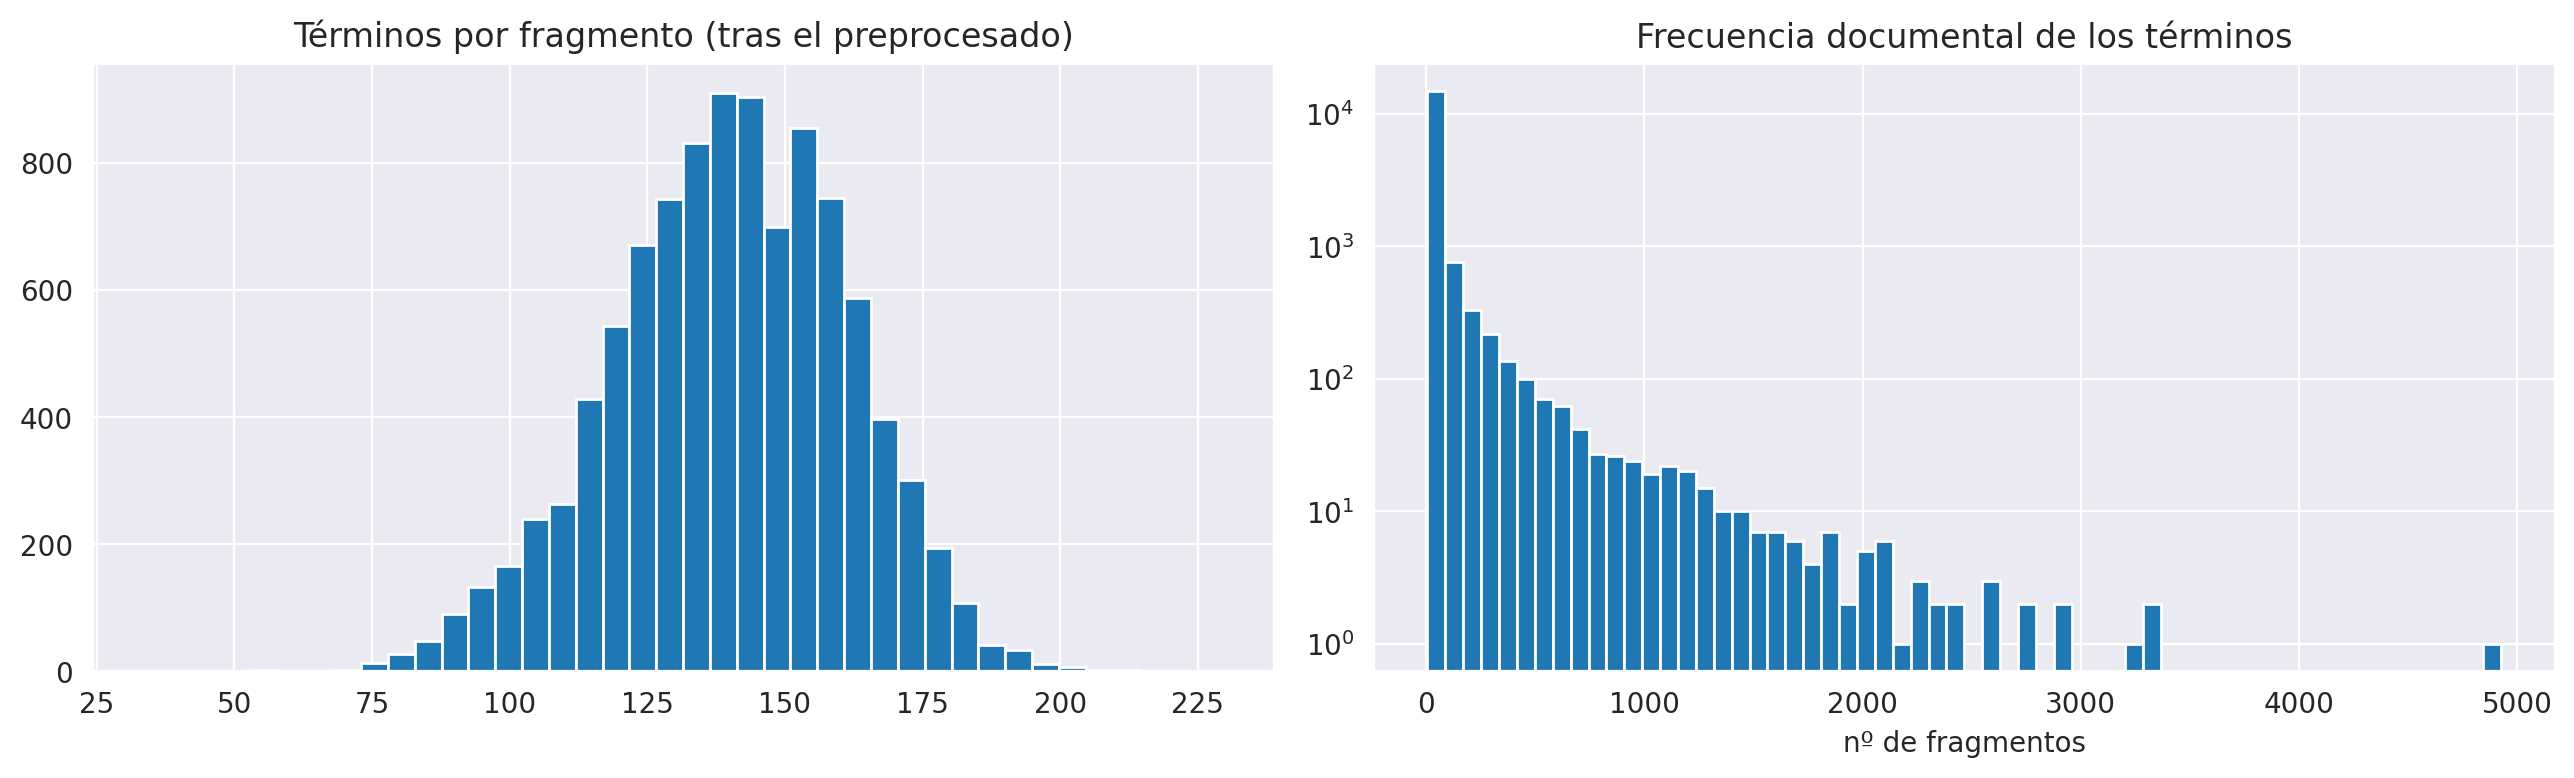

,10,366,395,318,102,346,81,101,493,746
término,base,performance,training,datum,task,learn,provide,system,framework,dataset
n_fragmentos,4928,3346,3314,3277,2942,2902,2745,2716,2607,2605


In [14]:
from gensim.models.phrases import Phrases
from gensim.corpora import Dictionary

# --- N-gramas ---
phrase_model = Phrases(chunk_lemmas, min_count=PHRASES_MIN_COUNT, threshold=PHRASES_THRESHOLD)
corpus = [phrase_model[doc] for doc in chunk_lemmas]          # lista de fragmentos, cada uno una lista de términos
top_phrases = Counter(t for doc in corpus for t in doc if '_' in t)
print('N-gramas más frecuentes:', [p for p, _ in top_phrases.most_common(15)])

# --- Diccionario y filtrado por frecuencia documental ---
D = Dictionary(corpus)
n_before = len(D)
D.filter_extremes(no_below=NO_BELOW, no_above=NO_ABOVE, keep_n=None)
print(f'Vocabulario: {n_before} términos -> {len(D)} tras filtrar (aparecen en >= {NO_BELOW} fragmentos y en <= {NO_ABOVE:.0%})')

chunk_bow = [D.doc2bow(doc) for doc in corpus]                 # representación bolsa de palabras de cada fragmento

def preprocess(texts):
    """Pipeline completo para textos nuevos (consultas): limpieza -> spaCy -> n-gramas. El diccionario se aplica luego con D.doc2bow."""
    return [phrase_model[tokens] for tokens in prepare_data(texts)]

# Términos por fragmento (sólo los que quedan en el diccionario) y términos más frecuentes en documentos
lengths = np.array([sum(c for _, c in bow) for bow in chunk_bow])
print(f'Términos por fragmento: media {lengths.mean():.0f}, mín {lengths.min()}, máx {lengths.max()} · fragmentos vacíos: {(lengths == 0).sum()}')

df_terms = pd.DataFrame({'término': [D[i] for i in D.keys()], 'n_fragmentos': [D.dfs[i] for i in D.keys()]})
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(lengths, bins=40); axes[0].set_title('Términos por fragmento (tras el preprocesado)')
axes[1].hist(df_terms['n_fragmentos'], bins=60, log=True); axes[1].set_title('Frecuencia documental de los términos'); axes[1].set_xlabel('nº de fragmentos')
plt.tight_layout(); plt.show()
display(df_terms.sort_values('n_fragmentos', ascending=False).head(10).T)

## **3. Consultas de prueba (known-item)**
---

El conjunto de consultas es el **conjunto de test de todo el proyecto**: se reutiliza en el Hito 2 y en el informe final. Por eso la **coherencia de cada consulta con su paper** es lo más importante de esta sección. Una consulta *known-item* es válida si (a) describe de verdad el paper relevante y (b) es lo bastante específica como para que ese paper sea *el* documento que se busca, no uno entre cientos del mismo tema.

**Procedimiento** (siguiendo el enunciado y añadiendo controles de coherencia):

1. **Muestreo estratificado**: fragmentos al azar, repartidos a partes iguales entre los 5 temas y con un solo fragmento por paper. El paper de origen es el único relevante (`relevant_ids`) y se guarda también el fragmento (`source_chunk`).
2. **Generación**: el LLM recibe el **título y el resumen del paper, además del fragmento**, y el área a la que pertenece, y escribe la consulta que haría un investigador para encontrarlo, **sin copiar** sus palabras. El resumen ancla la consulta al paper completo; el fragmento la hace más específica.
3. **Controles automáticos** (para cada candidata):
    * *Copia*: ningún grupo de 4 palabras seguidas puede coincidir con el fragmento, el título o el resumen.
    * *Alineación*: al menos `MIN_SHARED_TERMS` términos (lemas) de la consulta deben aparecer en el título/resumen; si no, es probable que hable de otra cosa.
    * *Juicio del LLM* en una llamada aparte: puntúa de 1 a 5 si la consulta **describe ese paper** (`match`) y si es **específica** (`specific`).
    * Longitud entre 6 y 30 palabras.
4. **Revisión manual** de al menos 10 consultas (celda `REVIEW`), con título, resumen y puntuaciones a la vista. Una consulta **sin revisar** sólo se conserva si pasa todos los controles automáticos; una **revisada a mano** manda siempre la decisión humana.
5. Se generan más candidatas de las necesarias (`N_CANDIDATES`) para que queden ≥ 30 tras descartar.

Dos cautelas que conviene mencionar en el análisis: los LLM tienden a **repetir los términos clave** del texto (favorece a los métodos léxicos) y otros papers del mismo tema pueden ser también relevantes para una consulta (cuentan como error aunque sean razonables).

In [28]:
AREA_NAMES = {'autonomous_vehicles': 'autonomous vehicles and self-driving', 'reinforcement_learning': 'reinforcement learning',
              'nlp': 'natural language processing', 'neural_networks': 'neural networks', 'deep_learning': 'deep learning'}

STYLES = {
    'simple': ("SHORT and simple: 4 to 8 words, a plain topic phrase like a quick keyword search that names the main "
               "subject of the paper (for example: graph neural networks for molecule property prediction). "
               "Do not chain technical terms and do not use 'with ... and ...' constructions.", 3, 10, 2),
    'conversational': ("a natural sentence of 8 to 14 words that starts like 'I am researching ...', 'I am looking for ...' "
                       "or 'Papers about ...' and states the single main idea of the paper (for example: I am researching "
                       "methods to speed up protein folding simulations).", 6, 20, 2),
    'detailed': ("a detailed query of 12 to 20 words that names the problem and the specific method or contribution.", 8, 30, 3),
}
STYLE_PATTERN = ['simple', 'conversational', 'detailed', 'simple', 'simple',
                 'conversational', 'detailed', 'simple', 'conversational', 'detailed']      # 4 simples, 3 + 3

GEN_PROMPT = """You are helping to build a test set for a search engine over scientific papers (arXiv).
You will receive the title and abstract of a paper and an excerpt from its full text.
Write ONE search query, in English, that a researcher who is looking for THIS paper could type.
Style of the query: {style_instruction}

Rules:
- The query must describe what the paper is about, so that it clearly belongs to the research area "{area}".
- Use the excerpt only to decide which topic of the paper to refer to; stay consistent with the paper as a whole.
- Use your own words: do NOT copy phrases from the title, the abstract or the excerpt; prefer paraphrases and synonyms.
- Do not include the title, author names, or numbers of sections, tables or figures.
- Output only the query, with no quotes and no explanation.

Research area: {area}
Title: {title}
Abstract: {abstract}
Excerpt:
{excerpt}
"""

JUDGE_PROMPT = """You are checking the quality of a test set for a search engine over scientific papers.
Research area: {area}
Paper title: {title}
Paper abstract: {abstract}

Search query: {query}

Rate the query with two integers from 1 to 5:
"match": how well the query describes THIS paper (1 = unrelated or about a different subject, 5 = clearly describes this paper's problem or contribution).
"specific": how specific the query is (1 = so generic that hundreds of papers in the area would match, 5 = it identifies a narrow set of papers).
Answer only with JSON, for example {{"match": 4, "specific": 3}}"""

# ---------------------------- acceso al LLM ----------------------------
_api_key = [None]

def api_key():
    """Clave del servidor UC3M: variable de entorno, secretos de Colab o entrada por teclado. Nunca se imprime ni se guarda."""
    if _api_key[0] is None:
        key = os.environ.get('UC3M_API_KEY')
        if not key and IN_COLAB:
            try:
                from google.colab import userdata
                key = userdata.get('UC3M_API_KEY')
            except Exception:
                key = None
        if not key:
            import getpass
            key = getpass.getpass('API key del servidor UC3M (está en el enunciado, sección 7): ')
        _api_key[0] = key
    return _api_key[0]

if not VERIFY_SSL:
    import urllib3
    urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

def call_llm(prompt, model, temperature=0.2, retries=3):
    url = UC3M_URL if LLM_BACKEND == 'uc3m' else OLLAMA_URL
    headers = {'X-API-KEY': api_key()} if LLM_BACKEND == 'uc3m' else {}
    payload = {'model': model, 'prompt': prompt, 'stream': False, 'options': {'temperature': temperature, 'seed': SEED}}
    error = None
    for attempt in range(retries):
        try:
            r = requests.post(url, headers=headers, json=payload, timeout=180, verify=VERIFY_SSL)
            r.raise_for_status()
            return r.json()['response']
        except (requests.RequestException, KeyError, ValueError) as e:
            error = type(e).__name__
            time.sleep(2 ** attempt)
    raise RuntimeError(f'El LLM no responde ({error})')

def strip_thinking(text):
    return re.sub(r'<think>.*?</think>', '', text, flags=re.S).strip()      # modelos tipo qwen3 razonan antes de responder

def clean_query(text):
    lines = strip_thinking(text).splitlines()
    text = lines[0] if lines else ''
    text = re.sub(r'^\W*(search\s+)?query\s*:\s*', '', text, flags=re.I)
    return text.strip().strip('"\'`').strip()

def parse_judge(text):
    text = strip_thinking(text)
    m, s = re.search(r'"?match"?\s*:\s*([1-5])', text), re.search(r'"?specific"?\s*:\s*([1-5])', text)
    return (int(m.group(1)) if m else None, int(s.group(1)) if s else None)

# ------------------------ muestreo estratificado ------------------------
def sample_source_chunks(n_total, seed):
    """Fragmentos al azar, repartidos a partes iguales entre temas y con un único fragmento por paper."""
    rng = random.Random(seed)
    topics = list(TOPICS)
    quota = {t: n_total // len(topics) + (i < n_total % len(topics)) for i, t in enumerate(topics)}
    picked = []
    for t in topics:
        pool = chunks_df[(chunks_df['topic'] == t) & (chunks_df['n_words'] >= 0.8 * CHUNK_WORDS)]
        doc_ids = sorted(pool['doc_id'].unique())
        rng.shuffle(doc_ids)
        for d in doc_ids[:quota[t]]:
            picked.append(pool[pool['doc_id'] == d].sample(1, random_state=rng.randrange(10 ** 6)).iloc[0])
    rng.shuffle(picked)
    return picked

In [29]:
def generate_candidates():
    cands = []
    for i, row in enumerate(tqdm(sample_source_chunks(N_CANDIDATES, SEED + 2), desc='consultas'), 1):
        doc = docs_by_id[row['doc_id']]
        style = STYLE_PATTERN[(i - 1) % len(STYLE_PATTERN)]
        fields = dict(area=AREA_NAMES[row['topic']], title=doc['title'], abstract=doc['abstract'])
        try:
            query = clean_query(call_llm(GEN_PROMPT.format(excerpt=row['text'], style_instruction=STYLES[style][0], **fields),
                                         LLM_MODEL, temperature=0.3))
            match, specific = parse_judge(call_llm(JUDGE_PROMPT.format(query=query, **fields), JUDGE_MODEL, temperature=0.0))
        except RuntimeError as e:
            print(f'  candidata {i} omitida: {e}')
            continue
        cands.append({'qid': f'q{i:02d}', 'query': query, 'relevant_ids': [row['doc_id']], 'source_chunk': row['chunk_id'],
                      'topic': row['topic'], 'style': style, 'judge_match': match, 'judge_specific': specific})
    return cands

cached = read_jsonl(QUERIES_CAND_FILE) if os.path.exists(QUERIES_CAND_FILE) else []
if cached and 'style' in cached[0] and not REGENERATE_QUERIES:
    print('Reutilizando', QUERIES_CAND_FILE, '(así la revisión manual sigue siendo válida). REGENERATE_QUERIES=True para rehacerlas.')
    cands = cached
else:
    if cached:
        print('Las candidatas guardadas no tienen estilo (versión anterior): se regeneran.')
    cands = generate_candidates()
    write_jsonl(QUERIES_CAND_FILE, cands)
print(len(cands), 'candidatas')
print(pd.Series([c['style'] for c in cands]).value_counts().to_string())

Las candidatas guardadas no tienen estilo (versión anterior): se regeneran.


consultas:   0%|          | 0/60 [00:00<?, ?it/s]

API key del servidor UC3M (está en el enunciado, sección 7): ··········
  candidata 1 omitida: El LLM no responde (HTTPError)


KeyboardInterrupt: 

In [33]:
_api_key[0] = None          # olvida la clave anterior; se vuelve a pedir
r = requests.post(UC3M_URL, headers={'X-API-KEY': api_key()},
                  json={'model': LLM_MODEL, 'prompt': 'Say hi', 'stream': False},
                  timeout=60, verify=VERIFY_SSL)
print(r.status_code, r.text[:300])

API key del servidor UC3M (está en el enunciado, sección 7): ··········
502 <html>
<head><title>502 Bad Gateway</title></head>
<body>
<center><h1>502 Bad Gateway</h1></center>
<hr><center>nginx/1.26.3 (Ubuntu)</center>
</body>
</html>



### *3.1. Controles automáticos de coherencia*

In [ ]:
def words_of(text):
    return re.findall(r'[a-z0-9]+', text.lower())

def ngram_copies(query, reference, n=4):
    """Nº de grupos de n palabras consecutivas de la consulta que aparecen literalmente en el texto de referencia."""
    q, r = words_of(query), words_of(reference)
    ref_grams = {tuple(r[i:i + n]) for i in range(len(r) - n + 1)}
    return sum(tuple(q[i:i + n]) in ref_grams for i in range(len(q) - n + 1))

chunk_text_by_id = dict(zip(chunks_df['chunk_id'], chunks_df['text']))
cand_by_id = {c['qid']: c for c in cands}

# lemas de cada consulta y del título + resumen de su paper (sin n-gramas, para comparar términos sueltos)
q_lemmas = prepare_data([c['query'] for c in cands])
a_lemmas = prepare_data([docs_by_id[c['relevant_ids'][0]]['title'] + '. ' + docs_by_id[c['relevant_ids'][0]]['abstract'] for c in cands])

for c, ql, al in zip(cands, q_lemmas, a_lemmas):
    doc = docs_by_id[c['relevant_ids'][0]]
    reference = doc['title'] + ' ' + doc['abstract']
    _, min_w, max_w, min_specific = STYLES[c['style']]
    c['n_words'] = len(c['query'].split())
    c['copy4'] = ngram_copies(c['query'], chunk_text_by_id[c['source_chunk']]) + ngram_copies(c['query'], reference)
    c['shared_terms'] = len(set(ql) & set(al))
    reasons = []
    if not min_w <= c['n_words'] <= max_w:
        reasons.append(f'longitud ({c["n_words"]} palabras; estilo {c["style"]}: {min_w}-{max_w})')
    if c['copy4'] > 0:
        reasons.append('copia literal de 4+ palabras')
    if c['shared_terms'] < MIN_SHARED_TERMS:
        reasons.append('casi sin términos del título/resumen')
    if c['judge_match'] is None or c['judge_match'] < MIN_JUDGE_MATCH:
        reasons.append(f'el LLM no ve que describa el paper (match={c["judge_match"]})')
    if c['judge_specific'] is None or c['judge_specific'] < min_specific:
        reasons.append(f'demasiado genérica (specific={c["judge_specific"]}, mínimo {min_specific})')
    c['auto'] = 'ok' if not reasons else 'revisar'
    c['reasons'] = '; '.join(reasons)

auto_df = pd.DataFrame(cands)[['qid', 'topic', 'style', 'query', 'judge_match', 'judge_specific', 'shared_terms', 'copy4', 'auto', 'reasons']]
print(f'{(auto_df["auto"] == "ok").sum()} de {len(auto_df)} candidatas superan todos los controles automáticos')
print(pd.crosstab(auto_df['topic'], auto_df['auto']).to_string())
print(pd.crosstab(auto_df['style'], auto_df['auto']).to_string())
display(auto_df.sort_values(['auto', 'topic']).reset_index(drop=True))

spaCy:   0%|          | 0/60 [00:00<?, ?it/s]

spaCy:   0%|          | 0/60 [00:00<?, ?it/s]

23 de 60 candidatas superan todos los controles automáticos
auto                    ok  revisar
topic                              
autonomous_vehicles      3        9
deep_learning            2       10
neural_networks          7        5
nlp                      7        5
reinforcement_learning   4        8


,qid,topic,query,judge_match,judge_specific,shared_terms,copy4,auto,reasons
0,q34,autonomous_vehicles,Autonomous vehicles occlusion-aware motion planning collision avoidance guarantee with reachability analysis and tree-based trajectory planning.,5,4,14,0,ok,
1,q46,autonomous_vehicles,Self-driving vehicles migrating between roadside units with dynamic pruning for efficient computation and exploration.,5,4,9,0,ok,
2,q53,autonomous_vehicles,Improving autonomous driving with reinforcement learning by integrating trajectory planning and kinematic feasibility checks for safer navigation,5,4,11,0,ok,
3,q02,deep_learning,Can deep learning models distinguish between high-quality and low-quality news articles based on linguistic features?,5,4,12,0,ok,
4,q03,deep_learning,deep learning vs feature engineering for coin grading with limited data and class imbalance,5,4,8,0,ok,
5,q06,neural_networks,Evaluating neural network performance on generated optimization test functions with diverse landscape properties.,5,4,10,0,ok,
6,q07,neural_networks,Biologically plausible neural network for anomaly detection with adaptive threshold and Laplacian regularization of synaptic connections,5,4,5,0,ok,
7,q19,neural_networks,fractal dimensions in neural network layers under varying scales and their implications for hierarchical abstraction,5,4,8,0,ok,
8,q44,neural_networks,Genetic programming for multivariate activation functions with missing data indicators and confidence scores in neural networks.,5,4,12,0,ok,
9,q55,neural_networks,neural networks for symbolic regression of high-dimensional noisy data using sparse feature extraction,5,4,7,0,ok,


### *3.2. Revisión manual*

**Obligatorio**: revisad **al menos 10 consultas** (`MIN_REVIEWED`), repartidas entre los 5 temas, empezando por las marcadas como `revisar`, y documentad la decisión en `REVIEW`. Para cada una, `inspect_query('q07')` muestra el título y el resumen del paper, la consulta y el fragmento de origen. Preguntas que hay que hacerse:

* **Coherencia**: ¿la consulta describe este paper y pertenece al tema indicado? ¿Un investigador que busca eso encontraría este paper?
* **Especificidad**: ¿valdría igual para decenas de papers del tema? Si es así, descartarla (*genérica*).
* **No trivial**: ¿copia el título o frases del resumen? Entonces es trivial para un método léxico (*trivial*).
* **No ambigua**: ¿hay otro paper del corpus que respondería igual de bien? (*ambigua*)

Formato: `'q07': ('discard', 'genérica: valdría para cualquier paper de RL')` o `'q03': ('ok', 'coherente; parafrasea bien')`.

In [ ]:
def inspect_query(qid):
    c = cand_by_id[qid]
    doc = docs_by_id[c['relevant_ids'][0]]
    print(f'[{qid}] tema: {c["topic"]} · {c["relevant_ids"][0]} · auto: {c["auto"]} {c["reasons"]}')
    print('TÍTULO  :', doc['title'])
    print('RESUMEN :', textwrap.fill(doc['abstract'], 120, subsequent_indent=' ' * 10))
    print('CONSULTA:', c['query'], f'  (match={c["judge_match"]}, specific={c["judge_specific"]})')
    print('FRAGMENTO DE ORIGEN:', textwrap.fill(chunk_text_by_id[c['source_chunk']][:700], 120) + ' ...\n')

# Empezad por las que los controles automáticos han marcado:
for qid in [c['qid'] for c in cands if c['auto'] == 'revisar'][:3]:
    inspect_query(qid)

[q01] tema: reinforcement_learning · doc_2504.03160 · auto: revisar copia literal de 4+ palabras
TÍTULO  : DeepResearcher: Scaling Deep Research via Reinforcement Learning in Real-world Environments
RESUMEN : Large Language Models (LLMs) equipped with web search capabilities have demonstrated impressive potential for deep
          research tasks. However, current approaches predominantly rely on either manually engineered prompts (prompt
          engineering-based) with brittle performance or reinforcement learning within controlled Retrieval-Augmented
          Generation (RAG) environments (RAG-based) that fail to capture the complexities of real-world interaction. In
          this paper, we introduce DeepResearcher, the first comprehensive framework for end-to-end training of LLM-
          based deep research agents through scaling reinforcement learning (RL) in real-world environments with
          authentic web search interactions. Unlike RAG-based approaches that assume all 

In [ ]:
# ⚠️  COMPLETAD ESTA CELDA TRAS REVISAR A MANO (al menos MIN_REVIEWED consultas, de todos los temas)
REVIEW = {
    # 'q03': ('ok',      'coherente con el paper; parafrasea bien'),
    # 'q07': ('discard', 'genérica: valdría para cualquier paper de RL'),
    # 'q12': ('discard', 'copia frases del resumen: trivial para BM25'),
}

In [ ]:
unknown = [q for q in REVIEW if q not in cand_by_id]
bad_values = [q for q, (decision, _) in REVIEW.items() if decision not in ('ok', 'discard')]
assert not unknown, f'qid inexistentes en REVIEW: {unknown}'
assert not bad_values, f"la decisión debe ser 'ok' o 'discard': {bad_values}"

def decide(c):
    """Decisión humana si la hay; si no, sólo se conserva lo que supera todos los controles automáticos."""
    if c['qid'] in REVIEW:
        return REVIEW[c['qid']][0]
    return 'ok' if c['auto'] == 'ok' else 'discard'

for c in cands:
    c['final'] = decide(c)
kept = [c for c in cands if c['final'] == 'ok']

# --- guardado: consultas finales (formato del enunciado + fragmento de origen) y documentación de la revisión ---
write_jsonl(QUERIES_FILE, [{'qid': c['qid'], 'query': c['query'], 'relevant_ids': c['relevant_ids'], 'source_chunk': c['source_chunk']}
                           for c in kept])
pd.DataFrame([{'qid': c['qid'], 'topic': c['topic'], 'query': c['query'], 'auto': c['auto'], 'auto_reasons': c['reasons'],
               'judge_match': c['judge_match'], 'judge_specific': c['judge_specific'],
               'manual_decision': REVIEW.get(c['qid'], ('', ''))[0], 'manual_note': REVIEW.get(c['qid'], ('', ''))[1],
               'final': c['final']} for c in cands]).astype({'judge_match': 'Int64', 'judge_specific': 'Int64'}).to_csv(REVIEW_FILE, index=False)

n_reviewed = len(REVIEW)
min_topic = 1 if SMOKE_TEST else 5
per_topic = Counter(c['topic'] for c in kept)
print(f'Candidatas: {len(cands)} · revisadas a mano: {n_reviewed} · conservadas: {len(kept)} · guardadas en {QUERIES_FILE}')
print('Consultas finales por tema:', {t: per_topic.get(t, 0) for t in TOPICS})
if n_reviewed < MIN_REVIEWED:
    print(f'⚠️  FALTA LA REVISIÓN MANUAL: {n_reviewed} de {MIN_REVIEWED} consultas revisadas. Completad REVIEW y volved a ejecutar desde la celda de REVIEW hasta el final.')
if len(kept) < N_QUERIES_MIN:
    print(f'⚠️  Sólo {len(kept)} consultas válidas (mínimo {N_QUERIES_MIN}): subid N_CANDIDATES y regenerad (REGENERATE_QUERIES=True).')
if any(per_topic.get(t, 0) < min_topic for t in TOPICS):
    print(f'⚠️  Algún tema tiene menos de {min_topic} consultas: el conjunto de test no cubre bien los 5 temas.')

# Vista final por tema: cada consulta junto al paper que se considera relevante (comprobación visual de la coherencia)
coherence = pd.DataFrame([{'tema': c['topic'], 'qid': c['qid'], 'consulta': c['query'],
                           'paper relevante': docs_by_id[c['relevant_ids'][0]]['title'][:90]} for c in kept]).sort_values(['tema', 'qid'])
display(coherence.reset_index(drop=True))

## **4. Baselines de recuperación dispersa**
---

Los dos baselines trabajan sobre la **misma representación**: mismo preprocesado, mismo diccionario y mismos ≈ 10 000 fragmentos. Así, la diferencia entre ellos sólo se debe a la función de puntuación. Ambos puntúan **fragmentos**; en la sección 5 se pasa de fragmentos a documentos.

Las estadísticas globales (IDF, longitud media) se calculan **sobre los fragmentos**, no sobre los papers completos.



### *4.1. TF-IDF + similitud coseno*

* **Implementación**: Gensim `TfidfModel` con sus opciones por defecto: $\text{tf}$ = conteo bruto, $\text{idf} = \log_2 (N/\text{df})$ y cada vector normalizado a norma L2. $N$ es el número de fragmentos.
* La consulta se vectoriza con el mismo modelo; al estar ambos vectores normalizados, la similitud coseno es un producto escalar.

In [ ]:
from gensim.models import TfidfModel
from gensim.matutils import corpus2csc

tfidf = TfidfModel(chunk_bow)
n_chunks, n_terms = len(chunk_bow), len(D)

# Matrices dispersas (fragmentos x términos): conteos (para BM25) y pesos TF-IDF
X_counts = corpus2csc(chunk_bow, num_terms=n_terms, num_docs=n_chunks).T.tocsr()
X_tfidf = corpus2csc(tfidf[chunk_bow], num_terms=n_terms, num_docs=n_chunks).T.tocsr()
print(f'Matriz fragmentos x términos: {X_counts.shape}, {100 * X_counts.nnz / (n_chunks * n_terms):.2f} % de entradas no nulas')

def tfidf_scores(tokens):
    """Similitud coseno entre una consulta (lista de términos) y todos los fragmentos."""
    vec = np.zeros(n_terms)
    for term_id, weight in tfidf[D.doc2bow(tokens)]:
        vec[term_id] = weight
    return X_tfidf @ vec

### *4.2. BM25*

* **Implementación propia** con matrices dispersas (`BM25` más abajo), para poder reportar exactamente qué se calcula. Variante **Okapi BM25 con el IDF de Lucene**:

$$\text{BM25}(q, d) = \sum_{t \in q} \text{IDF}(t) \cdot \frac{f(t,d)\,(k_1 + 1)}{f(t,d) + k_1\left(1 - b + b\,\frac{|d|}{\text{avgdl}}\right)}, \qquad \text{IDF}(t) = \ln\left(1 + \frac{N - \text{df}(t) + 0.5}{\text{df}(t) + 0.5}\right)$$

* $f(t,d)$: conteo del término en el fragmento; $|d|$: nº de términos del fragmento tras el preprocesado; $\text{avgdl}$ y $N$, $\text{df}$: sobre el conjunto de **fragmentos**. La suma recorre los **términos distintos** de la consulta.
* **Parámetros**: $k_1 = 1.5$ (saturación de la frecuencia del término) y $b = 0.75$ (normalización por longitud). Son los valores habituales y los de `bm25s`. **No se ajustan sobre las consultas de prueba** (son el conjunto de test de todo el proyecto); la sección 5.3 sólo estudia la sensibilidad.
* Como comprobación, la celda de verificación compara la implementación con la fórmula escrita término a término y, si está instalada, con la librería `bm25s`.

In [ ]:
class BM25:
    """Okapi BM25 (IDF de Lucene) sobre una matriz dispersa de conteos fragmentos x términos."""
    def __init__(self, counts, k1=1.5, b=0.75):
        counts = sparse.csr_matrix(counts)
        self.k1, self.b = k1, b
        self.n_docs = counts.shape[0]
        self.doc_len = np.asarray(counts.sum(axis=1)).ravel().astype(float)
        self.avgdl = self.doc_len.mean()
        df = np.asarray((counts > 0).sum(axis=0)).ravel()
        self.idf = np.log1p((self.n_docs - df + 0.5) / (df + 0.5))
        coo = counts.tocoo()
        tf = coo.data.astype(float)
        norm = k1 * (1 - b + b * self.doc_len[coo.row] / self.avgdl)
        weights = self.idf[coo.col] * tf * (k1 + 1) / (tf + norm)           # peso BM25 de cada (fragmento, término)
        self.W = sparse.csc_matrix((weights, (coo.row, coo.col)), shape=counts.shape)

    def scores(self, term_ids):
        """Puntuación de todos los fragmentos para una consulta (ids de sus términos distintos)."""
        term_ids = sorted(set(term_ids))
        if not term_ids:
            return np.zeros(self.n_docs)
        return np.asarray(self.W[:, term_ids].sum(axis=1)).ravel()

bm25 = BM25(X_counts, k1=BM25_K1, b=BM25_B)
bm25_label = f'BM25 (k1={BM25_K1}, b={BM25_B})'

def query_term_ids(tokens):
    return [term_id for term_id, _ in D.doc2bow(tokens)]

def bm25_scores(tokens, model=None):
    return (model or bm25).scores(query_term_ids(tokens))

In [ ]:
# ---- Verificación 1: la fórmula escrita término a término coincide con la implementación matricial ----
X_csc = X_counts.tocsc()

def bm25_explicit(term_ids, row, k1=BM25_K1, b=BM25_B):
    dl = X_counts[row].sum()
    avgdl = X_counts.sum() / n_chunks
    score = 0.0
    for t in set(term_ids):
        df_t = X_csc[:, t].nnz
        idf = math.log(1 + (n_chunks - df_t + 0.5) / (df_t + 0.5))
        f = X_counts[row, t]
        score += idf * f * (k1 + 1) / (f + k1 * (1 - b + b * dl / avgdl))
    return score

rng_check = np.random.default_rng(SEED)
sample_terms = [int(t) for t in rng_check.choice(n_terms, size=6, replace=False)]
sample_rows = [int(r) for r in rng_check.choice(n_chunks, size=20, replace=False)]
ours = bm25.scores(sample_terms)
assert all(np.isclose(ours[r], bm25_explicit(sample_terms, r)) for r in sample_rows), 'BM25 no coincide con la fórmula'
print('✓ BM25 coincide con la fórmula explícita en', len(sample_rows), 'fragmentos')

# ---- Verificación 2 (opcional): coincide con la librería bm25s (mismo IDF Lucene, mismos k1 y b) ----
try:
    import bm25s
    vocab = D.token2id
    ref = bm25s.BM25(k1=BM25_K1, b=BM25_B, method='lucene')
    ref.index([[t for t in doc if t in vocab] for doc in corpus], show_progress=False)
    chosen_terms = [D[t] for t in sample_terms]
    ref_rows, _ = ref.retrieve([chosen_terms], k=10, show_progress=False)
    ours_top = set(np.argsort(-ours, kind='stable')[:10].tolist())
    print(f'✓ bm25s: {len(ours_top & set(ref_rows[0].tolist()))}/10 fragmentos en común en el top-10 (las diferencias, si las hay, son empates)')
except Exception as e:
    print('bm25s no disponible o API distinta; se omite la verificación 2 ->', type(e).__name__)

## **5. Evaluación**
---



### *5.1. Consultas y ranking a nivel de documento*

Las consultas se leen de `queries.jsonl` (lo que se evalúa es exactamente lo que se guarda en el repositorio) y se preprocesan **con la misma función** `preprocess` que los fragmentos.

**Protocolo** (indicaciones del profesor):

1. Se puntúan **todos los fragmentos** con cada método.
2. Cada documento recibe la **puntuación de su mejor fragmento**.
3. Los documentos se ordenan por esa puntuación, **sin repetidos**, y se queda con los K primeros. Los documentos con puntuación 0 (ningún término en común con la consulta) no cuentan como recuperados.
4. Se calculan **Recall@K** (K = 5 y 10; fracción de documentos relevantes en los K primeros, promediada sobre consultas) y **MRR** (media del inverso de la posición del primer documento relevante, 0 si no aparece).

Como complemento (opcional en el enunciado) se mide a nivel de **fragmento** si el fragmento de origen está entre los K primeros: es más exigente y informa sobre la estrategia de fragmentación.

Con un único documento relevante por consulta, Recall@K coincide con la fracción de consultas en las que el paper aparece entre los K primeros.

In [ ]:
queries = read_jsonl(QUERIES_FILE)
assert queries, 'queries.jsonl está vacío: revisad la sección 3'
query_tokens = preprocess([q['query'] for q in queries])
relevants = [set(q['relevant_ids']) for q in queries]
source_chunks = [q['source_chunk'] for q in queries]
q_topic = [docs_by_id[q['relevant_ids'][0]]['topic'] for q in queries]

print(f'{len(queries)} consultas')
for q, toks in list(zip(queries, query_tokens))[:3]:
    print(f'  {q["query"]}\n   -> {toks}')

# --- de fragmentos a documentos ---
doc_ids = docs_df['doc_id'].tolist()
doc_index = {d: i for i, d in enumerate(doc_ids)}
chunk_doc_idx = chunks_df['doc_id'].map(doc_index).to_numpy()
chunk_ids = chunks_df['chunk_id'].to_numpy()

def doc_scores_from_chunks(chunk_scores):
    """Paso 2: cada documento puntúa con su mejor fragmento."""
    scores = np.full(len(doc_ids), -np.inf)
    np.maximum.at(scores, chunk_doc_idx, chunk_scores)
    return scores

def top_docs(chunk_scores, k=MAX_DEPTH):
    """Pasos 3-4: documentos sin repetir, por puntuación decreciente (los de puntuación 0 no se consideran recuperados)."""
    scores = doc_scores_from_chunks(chunk_scores)
    order = np.argsort(-scores, kind='stable')[:k]
    return [doc_ids[i] for i in order if scores[i] > 0]

def top_chunks(chunk_scores, k=MAX_DEPTH):
    order = np.argsort(-chunk_scores, kind='stable')[:k]
    return [chunk_ids[i] for i in order if chunk_scores[i] > 0]

def rank_of_relevant(chunk_scores, doc_id):
    """Posición (1 = primero) del documento relevante en el ranking de documentos; inf si no se recupera."""
    scores = doc_scores_from_chunks(chunk_scores)
    s = scores[doc_index[doc_id]]
    return np.inf if s <= 0 else 1 + int((scores > s).sum())

# --- métricas ---
def recall_at_k(rankings, relevants, k):
    return float(np.mean([len(set(r[:k]) & rel) / len(rel) for r, rel in zip(rankings, relevants)]))

def reciprocal_ranks(rankings, relevants, k):
    out = []
    for r, rel in zip(rankings, relevants):
        out.append(next((1 / pos for pos, d in enumerate(r[:k], 1) if d in rel), 0.0))
    return np.array(out)

def mrr(rankings, relevants, k=10):
    return float(reciprocal_ranks(rankings, relevants, k).mean())

def chunk_hit_at_k(chunk_rankings, source_chunks, k):
    return float(np.mean([s in r[:k] for r, s in zip(chunk_rankings, source_chunks)]))

# Comprobación de las métricas con un caso hecho a mano
_r = [['a', 'b', 'c'], ['x', 'y', 'q'], ['p', 'r', 's']]
_rel = [{'b'}, {'q'}, {'zzz'}]
assert recall_at_k(_r, _rel, 1) == 0.0 and abs(recall_at_k(_r, _rel, 2) - 1 / 3) < 1e-12 and abs(recall_at_k(_r, _rel, 3) - 2 / 3) < 1e-12
assert abs(mrr(_r, _rel, 3) - (1 / 2 + 1 / 3 + 0) / 3) < 1e-12
print('✓ métricas verificadas con un caso hecho a mano')

In [ ]:
METHODS = {'TF-IDF + coseno': tfidf_scores, bm25_label: bm25_scores}
S = {name: np.vstack([fn(t) for t in query_tokens]) for name, fn in METHODS.items()}     # (consultas x fragmentos)

def evaluate(scores):
    doc_rank = [top_docs(s) for s in scores]
    chunk_rank = [top_chunks(s) for s in scores]
    res = {f'Recall@{k}': recall_at_k(doc_rank, relevants, k) for k in KS}
    res['MRR@10'] = mrr(doc_rank, relevants, 10)
    res['MRR@100'] = mrr(doc_rank, relevants, MAX_DEPTH)
    res.update({f'Fragmento origen @{k}': chunk_hit_at_k(chunk_rank, source_chunks, k) for k in KS})
    return res, doc_rank, chunk_rank

evaluated = {name: evaluate(S[name]) for name in S}
doc_rankings = {name: ev[1] for name, ev in evaluated.items()}
results_df = pd.DataFrame({name: ev[0] for name, ev in evaluated.items()}).T
print(f'Resultados sobre {len(queries)} consultas (nivel documento; las dos últimas columnas, a nivel de fragmento):')
display(results_df.round(3))

### *5.2. Incertidumbre y desglose por tema*

Con ≈ 30 consultas cada métrica tiene un **intervalo de confianza amplio**: una consulta de más o de menos mueve Recall@10 unos 3 puntos. Se calculan intervalos *bootstrap* (remuestreo de consultas) y, sobre todo, el de la **diferencia pareada** BM25 − TF-IDF: si incluye el 0, el conjunto de consultas no permite afirmar que un método sea mejor que el otro.

In [ ]:
names = list(S)
hit10 = {n: np.array([len(set(r[:10]) & rel) / len(rel) for r, rel in zip(doc_rankings[n], relevants)]) for n in names}
hit5 = {n: np.array([len(set(r[:5]) & rel) / len(rel) for r, rel in zip(doc_rankings[n], relevants)]) for n in names}
rr10 = {n: reciprocal_ranks(doc_rankings[n], relevants, 10) for n in names}

def bootstrap(values, n_boot=5000, seed=SEED):
    """Media e intervalo de confianza al 95 % por bootstrap sobre las consultas."""
    values = np.asarray(values, float)
    idx = np.random.default_rng(seed).integers(0, len(values), (n_boot, len(values)))
    lo, hi = np.percentile(values[idx].mean(axis=1), [2.5, 97.5])
    return values.mean(), lo, hi

rows = {}
for n in names:
    rows[n] = {label: '{:.3f} [{:.3f}, {:.3f}]'.format(*bootstrap(v)) for label, v in
               (('Recall@5', hit5[n]), ('Recall@10', hit10[n]), ('MRR@10', rr10[n]))}
print('Media [IC 95 % bootstrap]')
display(pd.DataFrame(rows).T)

a, b = names
for label, (va, vb) in {'Recall@10': (hit10[a], hit10[b]), 'MRR@10': (rr10[a], rr10[b])}.items():
    m, lo, hi = bootstrap(vb - va)
    print(f'Diferencia {label}  ({b}) − ({a}): {m:+.3f}  IC 95 % [{lo:+.3f}, {hi:+.3f}]  ->',
          'el intervalo no incluye 0' if lo > 0 or hi < 0 else 'el intervalo incluye 0: no hay evidencia de diferencia')

# Desglose por tema (el tema es el del paper relevante)
short = {a: 'TF-IDF', b: 'BM25'}
rows = []
for t in TOPICS:
    idx = [i for i, qt in enumerate(q_topic) if qt == t]
    if idx:
        row = {'tema': t, 'consultas': len(idx)}
        for n in names:
            row[f'Recall@10 {short[n]}'] = hit10[n][idx].mean()
            row[f'MRR@10 {short[n]}'] = rr10[n][idx].mean()
        rows.append(row)
display(pd.DataFrame(rows).round(3).set_index('tema'))

In [ ]:
# Curva Recall@K: ¿a partir de qué K se recupera el paper?
ks = range(1, 51)
for n in names:
    plt.plot(list(ks), [recall_at_k(doc_rankings[n], relevants, k) for k in ks], label=n)
plt.axvline(5, color='gray', ls=':'); plt.axvline(10, color='gray', ls=':')
plt.xlabel('K'); plt.ylabel('Recall@K'); plt.ylim(0, 1.02); plt.title('Recall@K a nivel de documento'); plt.legend()
plt.show()

### *5.3. Sensibilidad de BM25 a $k_1$ y $b$*

Sólo para **estudiar la sensibilidad**, no para elegir parámetros: el conjunto de consultas es el test final del proyecto, así que el baseline que se reporta usa los valores por defecto. Si más adelante queréis ajustar $k_1$ y $b$, separad antes unas consultas de desarrollo.

Casos extremos: $b = 0$ desactiva la normalización por longitud; $b = 1$ la aplica por completo; $k_1 \to 0$ convierte el TF en binario (sólo importa si el término aparece).

In [ ]:
rows = []
for k1 in (0.5, 1.2, 1.5, 2.0):
    for b_ in (0.0, 0.5, 0.75, 1.0):
        model = BM25(X_counts, k1=k1, b=b_)
        rankings = [top_docs(bm25_scores(t, model)) for t in query_tokens]
        rows.append({'k1': k1, 'b': b_, 'Recall@5': recall_at_k(rankings, relevants, 5),
                     'Recall@10': recall_at_k(rankings, relevants, 10), 'MRR@10': mrr(rankings, relevants, 10)})
grid = pd.DataFrame(rows)
display(grid.pivot(index='k1', columns='b', values='MRR@10').round(3).rename_axis(index='k1', columns='b  (MRR@10)'))
display(grid.pivot(index='k1', columns='b', values='Recall@10').round(3).rename_axis(index='k1', columns='b  (Recall@10)'))

## **6. Análisis de fallos**
---

Nos fijamos en las consultas en las que **fallan los dos métodos** (el paper relevante no aparece entre los 10 primeros con ninguno de ellos) y, para cada una, miramos:

* el **rango** del paper relevante con cada método (inf = no se recupera: ningún término en común);
* qué fracción de los términos de la consulta aparecen en el **fragmento de origen** (si el LLM usó otras palabras, un método léxico no puede encontrarlo: *vocabulary mismatch*);
* qué **papers** quedan por delante y de qué tema son (¿son competidores igual de razonables? ¿la consulta era demasiado genérica?).

Las "pistas" automáticas son sólo orientativas: hay que **leer** las consultas y los papers antes de sacar conclusiones.

In [ ]:
chunk_tokens_by_id = dict(zip(chunks_df['chunk_id'], corpus))
rank_cols = {n: [rank_of_relevant(S[n][i], queries[i]['relevant_ids'][0]) for i in range(len(queries))] for n in names}

per_query = pd.DataFrame({'qid': [q['qid'] for q in queries], 'tema': q_topic,
                          'rango ' + short[a]: rank_cols[a], 'rango ' + short[b]: rank_cols[b]})
# fracción de términos de la consulta presentes en su fragmento de origen
per_query['solape con el fragmento'] = [
    np.mean([t in set(chunk_tokens_by_id[q['source_chunk']]) for t in toks]) if toks else 0.0
    for q, toks in zip(queries, query_tokens)]

ra, rb = per_query['rango ' + short[a]], per_query['rango ' + short[b]]
both_fail = per_query[(ra > 10) & (rb > 10)]
only_one = per_query[((ra > 10) ^ (rb > 10))]
print(f'Fallan ambos métodos: {len(both_fail)} consultas · falla sólo uno: {len(only_one)} · aciertan ambos: {len(per_query) - len(both_fail) - len(only_one)}')

hit = (rb <= 10)
print('\nSolape medio de la consulta con su fragmento de origen:',
      f'consultas con acierto en BM25 = {per_query.loc[hit, "solape con el fragmento"].mean():.2f} · '
      f'con fallo = {per_query.loc[~hit, "solape con el fragmento"].mean():.2f}')

display(per_query.replace(np.inf, np.nan).round(2).sort_values('rango ' + short[b], ascending=False, na_position='first').head(10))

In [ ]:
def hint(i):
    toks = query_tokens[i]
    in_vocab = [t for t in toks if t in D.token2id]
    src = set(chunk_tokens_by_id[queries[i]['source_chunk']])
    missing = [t for t in set(toks) if t not in src]
    if not in_vocab:
        return 'ningún término de la consulta está en el vocabulario', missing
    if toks and len(missing) / len(set(toks)) >= 0.5:
        return 'vocabulary mismatch: la mitad o más de los términos de la consulta no aparecen en el fragmento de origen', missing
    return 'los términos aparecen, pero otros papers los usan con más peso (consulta poco discriminativa o competidores razonables)', missing

for i in both_fail.index:
    q, doc = queries[i], docs_by_id[queries[i]['relevant_ids'][0]]
    pista, missing = hint(i)
    print('=' * 120)
    print(f'[{q["qid"]}] tema: {q_topic[i]}')
    print('CONSULTA  :', q['query'])
    print('TÉRMINOS  :', query_tokens[i])
    print('RELEVANTE :', doc['title'][:100])
    print(f'RANGO     : {short[a]} = {ra[i]}, {short[b]} = {rb[i]}')
    print('TÉRMINOS AUSENTES DEL FRAGMENTO DE ORIGEN:', sorted(missing))
    print('PISTA     :', pista)
    for n in names:
        print(f'  top-3 {short[n]}:', ' | '.join(f'{docs_by_id[d]["title"][:55]} ({docs_by_id[d]["topic"]})' for d in top_docs(S[n][i], 3)))
if both_fail.empty:
    print('Ninguna consulta falla con ambos métodos. Mirad igualmente las que fallan con uno solo (tabla anterior).')

### *Análisis (completar tras ejecutar)*

**Escribid aquí vuestras conclusiones sobre los fallos**, con ejemplos concretos del análisis anterior (qid y qué pasó). Guía:

* **¿Qué tipos de fallo hay y cuántos de cada?** Por ejemplo: *vocabulary mismatch* (la consulta usa sinónimos y el paper otras palabras), consultas demasiado genéricas, papers competidores del mismo tema que responden igual de bien (el solapamiento entre RL / deep learning / redes neuronales es esperable), fragmentos de origen poco informativos (cabecera, tabla...).
* **¿En qué temas se falla más y por qué?**
* **¿Qué método gana y con qué evidencia?** Citad el intervalo de la diferencia pareada: con ≈ 30 consultas probablemente no sea concluyente.
* **¿Hay sesgo hacia los métodos léxicos?** El solape medio entre consultas y fragmento (arriba) indica cuánto copia el LLM, lo que favorece a TF-IDF/BM25 frente a los métodos densos del Hito 2.
* **¿Qué cambiaríais?** (consultas más parafraseadas, más consultas para estrechar los intervalos, otra fragmentación, qué esperáis de la recuperación densa y/o híbrida en el Hito 2).

## **7. Cierre del hito**
---

Lista de comprobación y borrador de `MILESTONE_1.md` con los números ya rellenados.

In [ ]:
status = [
    ('Corpus de miles de papers', len(docs_df) >= 1000, f'{len(docs_df)} papers, {docs_df["topic"].nunique()} temas'),
    ('Fragmentos de 200-400 palabras con solape del 10-20 %', 200 <= CHUNK_WORDS <= 400 and 0.10 <= CHUNK_OVERLAP <= 0.20,
     f'{CHUNK_WORDS} palabras, {CHUNK_OVERLAP:.0%} de solape, {len(chunks_df)} fragmentos indexados'),
    ('Cada fragmento con id propio y el de su documento', bool(chunks_df['chunk_id'].is_unique and chunks_df['doc_id'].notna().all()), ''),
    (f'Al menos {N_QUERIES_MIN} consultas known-item', len(queries) >= N_QUERIES_MIN, f'{len(queries)} consultas en queries.jsonl'),
    (f'Al menos {MIN_REVIEWED} consultas revisadas a mano y documentadas', len(REVIEW) >= MIN_REVIEWED, f'{len(REVIEW)} en REVIEW -> {os.path.basename(REVIEW_FILE)}'),
    ('Consultas de los 5 temas', all(Counter(q_topic).get(t, 0) > 0 for t in TOPICS), str(dict(Counter(q_topic)))),
    ('TF-IDF + coseno y BM25 evaluados (Recall@5, Recall@10, MRR)', True, bm25_label),
    ('Análisis de fallos escrito en la sección 6', None, 'manual: completad la celda de análisis'),
    ('Declaración de uso de herramientas de IA en MILESTONE_1.md', None, 'manual'),
]
for name, ok, detail in status:
    print(('✅' if ok else '⬜' if ok is None else '❌'), name, '·', detail)

In [ ]:
def md_table(df):
    cols = list(df.columns)
    lines = ['| Método | ' + ' | '.join(cols) + ' |', '|---|' + '---|' * len(cols)]
    lines += [f'| {name} | ' + ' | '.join(f'{v:.3f}' for v in row) + ' |' for name, row in df.iterrows()]
    return '\n'.join(lines)

draft = f"""# Hito 1 — Baseline de recuperación (grupo: ___)

## Qué se ha hecho
- **Corpus**: {len(docs_df)} papers de arXiv ({DATE_START} a {DATE_END}), {PAPERS_PER_TOPIC} por tema: {', '.join(TOPICS)}. Metadatos con la API de arXiv y PDFs del bucket público `gs://arxiv-dataset`.
- **Unidad de indexación**: fragmentos de {CHUNK_WORDS} palabras con solape del {CHUNK_OVERLAP:.0%}; se indexan {len(chunks_df)} fragmentos ({len(chunks_df) / len(docs_df):.1f} por paper de media: siempre el primero, con título y resumen, y el resto repartido por el texto).
- **Preprocesado**: spaCy `en_core_web_sm` (lemas de {', '.join(sorted(VALID_POS))}, sin stopwords), n-gramas con Gensim `Phrases`, términos en ≥ {NO_BELOW} fragmentos y en ≤ {NO_ABOVE:.0%}. Vocabulario final: {len(D)} términos.
- **Consultas**: {len(queries)} consultas known-item generadas con `{LLM_MODEL}` a partir de título + resumen + fragmento, con controles automáticos de coherencia (alineación con el resumen, no copia, juicio del LLM) y {len(REVIEW)} revisadas a mano (`queries_review.csv`).
- **Baselines**: TF-IDF + coseno (Gensim, tf bruta × log2(N/df), norma L2) y BM25 propio (Okapi, IDF de Lucene, k1={BM25_K1}, b={BM25_B}, estadísticas sobre fragmentos).

## Resultados (nivel documento, {len(queries)} consultas)
{md_table(results_df[['Recall@5', 'Recall@10', 'MRR@10']])}

(Intervalos de confianza y desglose por tema en el notebook.)

## Problemas encontrados y decisiones de diseño
- (completar: solapamiento entre temas, PDFs que fallan, tamaño del índice, consultas descartadas y por qué...)

## Análisis de fallos
- (completar con los hallazgos de la sección 6)

## Siguiente paso
- Hito 2: recuperación densa con embeddings y base de datos vectorial sobre los mismos fragmentos, comparada con estos baselines en las mismas consultas.

## Uso de herramientas de IA generativa
- `{LLM_MODEL}` (servidor de la UC3M): generación de las consultas de prueba y puntuación de su coherencia.
- (completar: otras herramientas usadas, p. ej. Claude para generar el esqueleto del notebook, y para qué)
"""
draft_path = os.path.join(OUT_DIR, 'MILESTONE_1_draft.md')
with open(draft_path, 'w', encoding='utf-8') as f:
    f.write(draft)
print('Borrador guardado en', draft_path, '-> copiadlo a MILESTONE_1.md, completadlo (una página) y entregadlo en Aula Global con el commit.')